In [1]:
import os
import scanpy
import scanpy as sc
import numpy as np
import pandas as pd

import random

random.seed(10)

In [2]:
# Directory h5ad data (Just test for a specific sample)
#os.chdir("/data/ciperi/Atlas_SSC/LUNG/GSE212109")
#directory_h5ad = "GSE212109.h5ad"
#adata_merged = scanpy.read_h5ad(directory_h5ad)

#print(adata_merged)

In [3]:
#print(adata_merged.raw.X)

In [4]:
import scanpy as sc
from pathlib import Path

# Base directory containing all GSE folders / h5ad files
base_dir = Path("/home/ciperi/data/Atlas_SSC/PBMCs")

# Find all .h5ad files inside directories starting with GSE
h5ad_files = sorted(
    #list(base_dir.glob("GSE*/**/*.h5ad")) +
    list(base_dir.glob("E-GEAD*/**/*.h5ad"))
)
print(h5ad_files)

print(f"Found {len(h5ad_files)} .h5ad files:")
for f in h5ad_files:
    print("  -", f)

# Read each dataset
adatas = []
for f in h5ad_files:
    print(f"\nReading {f.name} ...")
    adata = sc.read_h5ad(f)

    # Add a metadata column with the dataset name
    adata.obs["dataset"] = f.parent.name

    # Optionally make variable names unique
    adata.var_names_make_unique()

    adatas.append(adata)

# 🧬 --- Gene overlap comparison before merging ---
gene_lists = [set(a.var_names) for a in adatas]
shared_genes = set.intersection(*gene_lists)
all_genes = set.union(*gene_lists)

print("\n🧬 Gene overlap summary:")
print(f" - Total unique genes across all datasets: {len(all_genes):,}")
print(f" - Shared genes across all datasets: {len(shared_genes):,}")
print(f" - Percentage shared: {len(shared_genes)/len(all_genes)*100:.2f}%")

# Optional: show how many genes are shared per dataset
for i, a in enumerate(adatas):
    perc = len(shared_genes & set(a.var_names)) / len(a.var_names) * 100
    print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
    

# Merge all datasets
print("\nMerging all datasets ...")
adata_merged = adatas[0].concatenate(
    adatas[1:],
    batch_key="batch",
    batch_categories=[a.obs["dataset"][0] for a in adatas]
) #inner join by default (only the common one saved)

# Save merged dataset
output_file = base_dir / "merged_Atlas_SSC.h5ad"
#adata_merged.write(output_file)

print(f"\n✅ Merged AnnData object saved to:\n{output_file}")
print(adata_merged)


[PosixPath('/home/ciperi/data/Atlas_SSC/PBMCs/E-GEAD-872/E-GEAD-872.h5ad')]
Found 1 .h5ad files:
  - /home/ciperi/data/Atlas_SSC/PBMCs/E-GEAD-872/E-GEAD-872.h5ad

Reading E-GEAD-872.h5ad ...

🧬 Gene overlap summary:
 - Total unique genes across all datasets: 36,648
 - Shared genes across all datasets: 36,648
 - Percentage shared: 100.00%
   E-GEAD-872: 100.00% shared genes

Merging all datasets ...


/tmp/ipykernel_3858163/2873724700.py:45: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(f"   {a.obs['dataset'][0]}: {perc:.2f}% shared genes")
/tmp/ipykernel_3858163/2873724700.py:53: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  batch_categories=[a.obs["dataset"][0] for a in adatas]
/tmp/ipykernel_3858163/2873724700.py:50: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_merged = adatas[0].concatenate(



✅ Merged AnnData object saved to:
/home/ciperi/data/Atlas_SSC/PBMCs/merged_Atlas_SSC.h5ad
AnnData object with n_obs × n_vars = 263348 × 36648
    obs: 'n_genes', 'sample', 'total_counts', 'n_genes_by_counts', 'pct_counts_mt', 'pct_counts_ribosomal', 'pct_counts_hemoglobin', 'pct_counts_platelet', 'umi_gene_ratio', 'batch', 'geo_accession', 'organism_ch1', 'Characteristics[organism]', 'Characteristics[taxonomy_id]', 'Characteristics[isolate]', 'Characteristics[biomaterial_provider]', 'Characteristics[collection_date]', 'Characteristics[geo_loc_name]', 'Characteristics[age]', 'Characteristics[sex]', 'Characteristics[tissue]', 'Comment[BioSample]', 'Comment[sample_title]', 'Protocol_REF', 'Protocol_REF.1', 'Protocol_REF.2', 'Extract_Name', 'Material_Type', 'Comment[LIBRARY_LAYOUT]', 'Comment[LIBRARY_SELECTION]', 'Comment[LIBRARY_SOURCE]', 'Comment[LIBRARY_STRATEGY]', 'Comment[INSTRUMENT_MODEL]', 'Protocol_REF.3', 'Assay_Name', 'Comment[SRA_EXPERIMENT]', 'Comment[SRA_RUN]', 'Technology_Ty

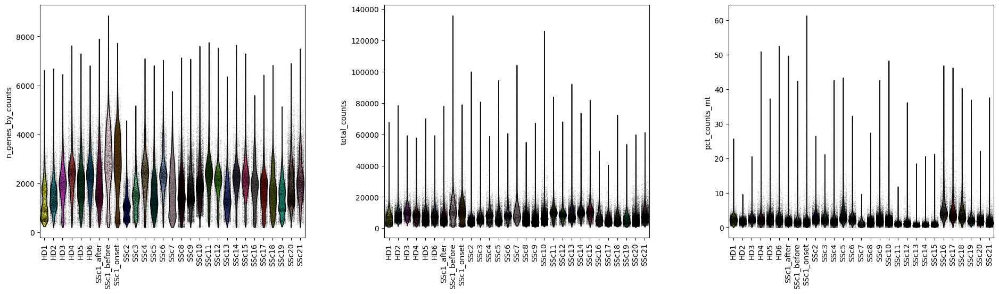

In [5]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)

sc.pl.violin(adata_merged,
    ["n_genes_by_counts","total_counts", "pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

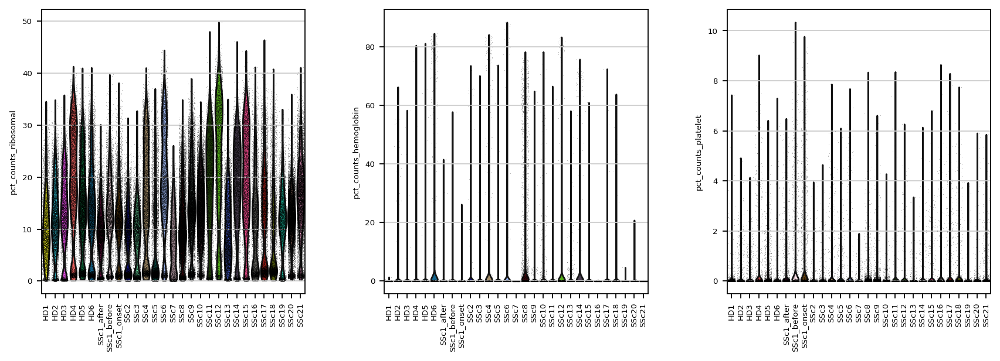

In [6]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

sc.pl.violin(adata_merged,
    ["pct_counts_ribosomal", "pct_counts_hemoglobin","pct_counts_platelet"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=False,
    size = 0.2 )  # 3 inches per row)  # width x height in inches)

In [7]:
adata_merged.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,Protocol_REF.3,Assay_Name,Comment[SRA_EXPERIMENT],Comment[SRA_RUN],Technology_Type,Array_Data_File,Protocol_REF.4,Derived_Array_Data_File,Factor_Value[disease],dataset
cell,,,,,,,,,,,,,,,,,,,,,
HD5_AAACCTGAGCTATGCT-1-E-GEAD-872,1612,HD5,5384.0,1612,6.240713,1.411590,0.000000,0.000000,3.339950,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
HD5_AAACCTGAGTAGGTGC-1-E-GEAD-872,1619,HD5,4838.0,1619,1.054155,13.290615,0.000000,0.000000,2.988264,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
HD5_AAACCTGCAAATCCGT-1-E-GEAD-872,1808,HD5,4460.0,1808,2.174888,16.053812,0.000000,0.000000,2.466814,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
HD5_AAACCTGCACATCCGG-1-E-GEAD-872,583,HD5,2108.0,583,5.075901,2.561670,0.000000,0.000000,3.615780,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
HD5_AAACCTGCACCAGGCT-1-E-GEAD-872,1724,HD5,10381.0,1724,0.587612,9.748579,0.000000,0.009633,6.021462,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SSc1_before_TTTGTCATCATATCGG-1-E-GEAD-872,2840,SSc1_before,10471.0,2840,1.852736,16.426320,0.009550,0.000000,3.686972,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
SSc1_before_TTTGTCATCCATGAGT-1-E-GEAD-872,4441,SSc1_before,17839.0,4441,1.855485,10.813387,0.000000,0.000000,4.016888,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872
SSc1_before_TTTGTCATCGAATCCA-1-E-GEAD-872,5837,SSc1_before,31532.0,5837,2.483192,19.519854,0.006343,0.000000,5.402090,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872


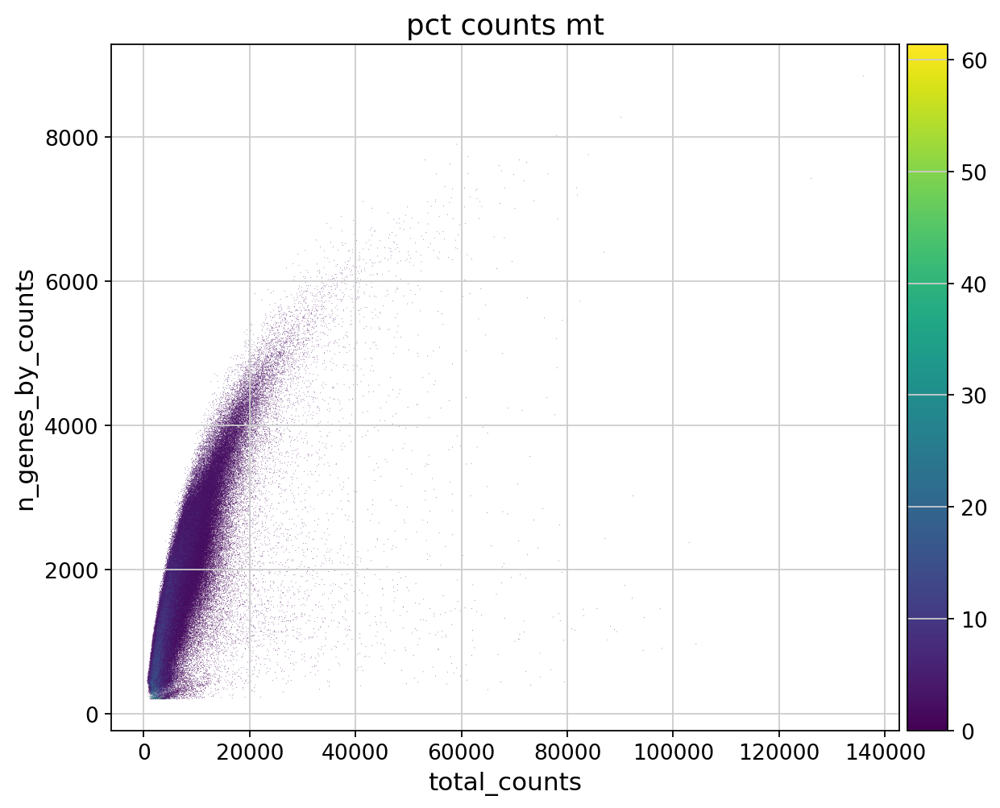

In [8]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_mt")

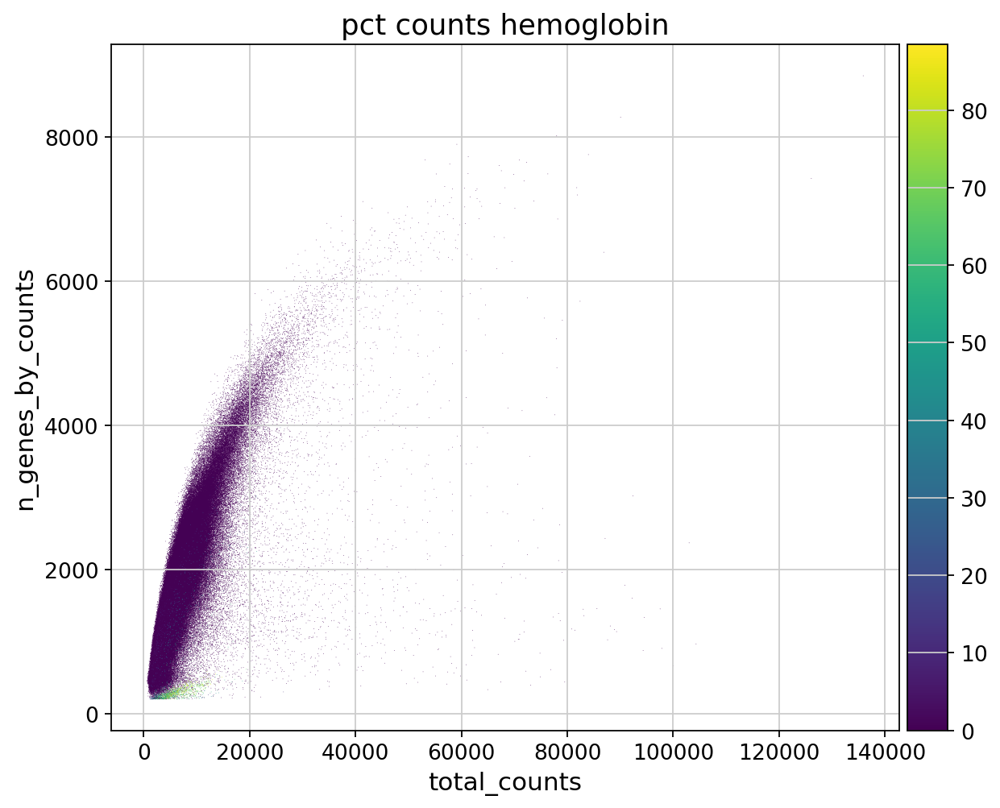

In [9]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_hemoglobin")

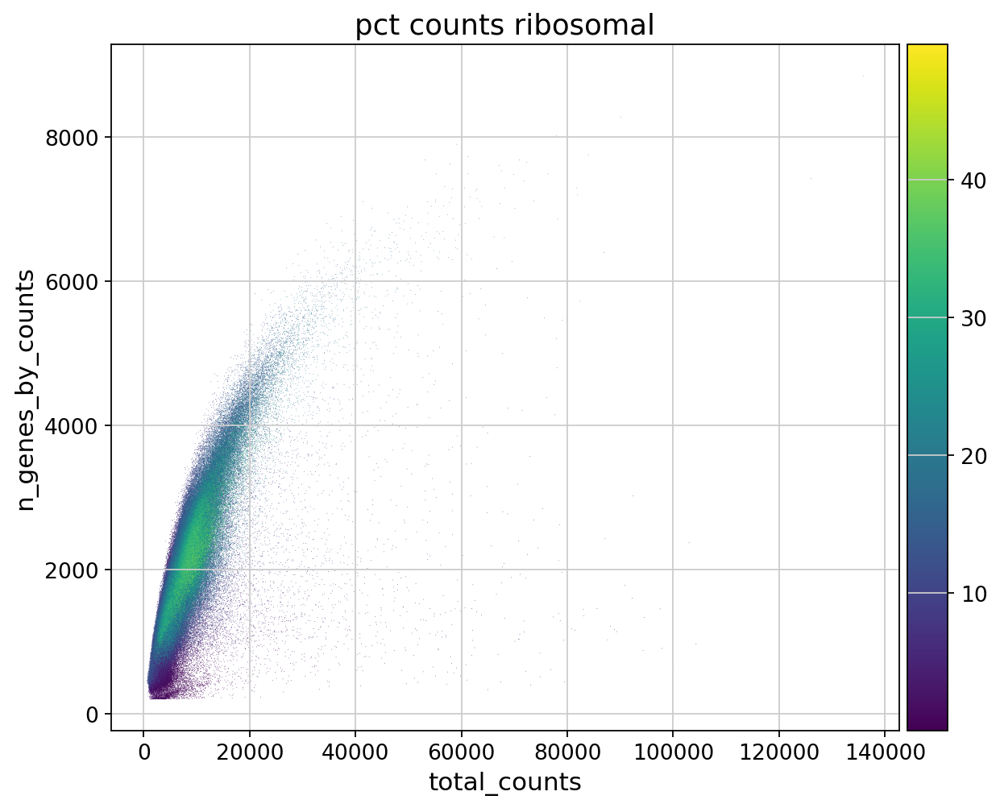

In [10]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_ribosomal")

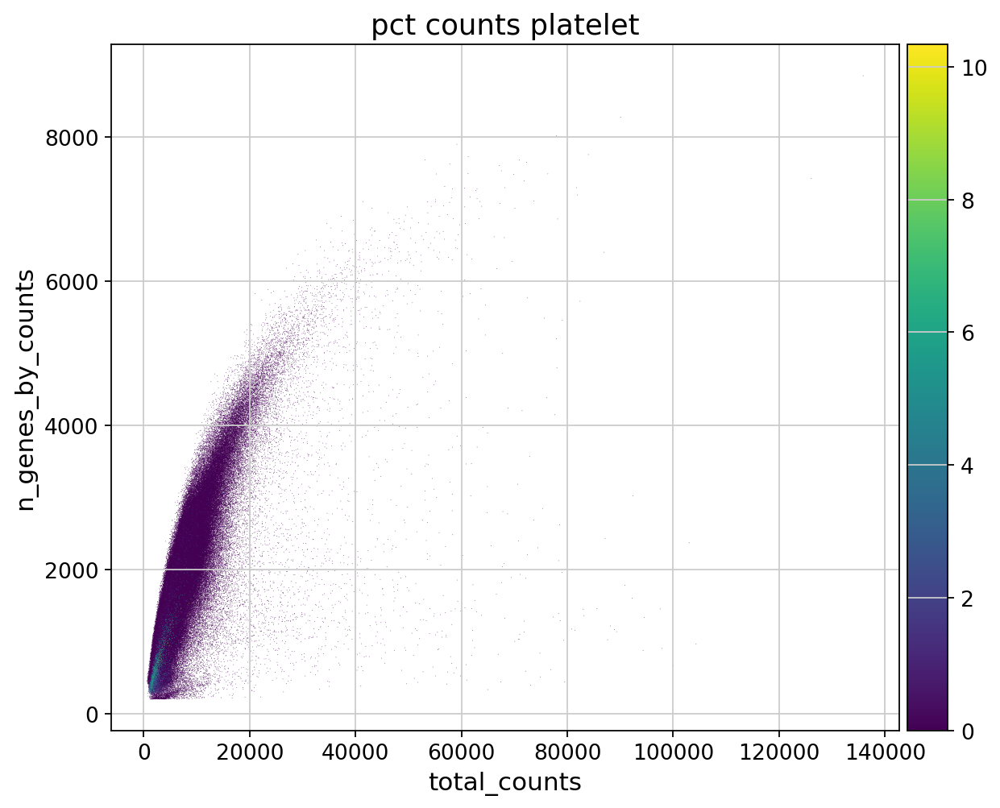

In [11]:
sc.pl.scatter(adata_merged, x="total_counts", y="n_genes_by_counts", color="pct_counts_platelet")

In [12]:
print(len(adata_merged.obs))

263348


# FILTERING THRESHOLD EXPLORATION

In [13]:
# Define thresholds for filtering
ribo_thresholds_down = np.arange(0, 15, 2.5)  # Ribosomal % from 0% to 15%
ribo_thresholds_up = np.arange(20, 50, 5)  # Ribosomal % from 20% to 60%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
263348


In [14]:
for ribo_down in ribo_thresholds_down:
    for ribo_up in ribo_thresholds_up:
        num_cells_removed = ((adata_merged.obs["pct_counts_ribosomal"] > ribo_down) & 
                             (adata_merged.obs["pct_counts_ribosomal"] < ribo_up)).sum()
        results.append([ribo_down, ribo_up, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Ribo_Threshold down > (%)", "Ribo_Threshold up < (%)", "Cells_Filtered"])
print(qc_table)

    Ribo_Threshold down > (%)  Ribo_Threshold up < (%)  Cells_Filtered
0                         0.0                       20          210178
1                         0.0                       25          236924
2                         0.0                       30          252896
3                         0.0                       35          261266
4                         0.0                       40          263133
5                         0.0                       45          263334
6                         2.5                       20          176142
7                         2.5                       25          202888
8                         2.5                       30          218860
9                         2.5                       35          227230
10                        2.5                       40          229097
11                        2.5                       45          229298
12                        5.0                       20          165089
13    

In [15]:
# Define thresholds for filtering
gene_thresholds = np.arange(5000, 9000, 1000)  # Gene Threshold
count_thresholds = np.arange(30000, 70000, 10000)  # Count Threshold
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
263348


In [16]:
for gene in gene_thresholds:
    for count in count_thresholds:
        num_cells_removed = ((adata.obs["total_counts"] < gene) & 
                             (adata.obs["n_genes_by_counts"] < count)).sum()
        results.append([gene, count, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Gene number < (%)", "Reads/UMI counts < (%)", "Cells_Filtered"])
print(qc_table)

    Gene number < (%)  Reads/UMI counts < (%)  Cells_Filtered
0                5000                   30000           81814
1                5000                   40000           81814
2                5000                   50000           81814
3                5000                   60000           81814
4                6000                   30000          108473
5                6000                   40000          108473
6                6000                   50000          108473
7                6000                   60000          108473
8                7000                   30000          135000
9                7000                   40000          135000
10               7000                   50000          135000
11               7000                   60000          135000
12               8000                   30000          161028
13               8000                   40000          161028
14               8000                   50000          161028
15      

In [17]:
# Define thresholds for filtering
mito_thresholds = np.arange(5, 25, 5)  # Ribosomal % from 2.5% to 15%
hemo_thresholds = np.arange(0.5, 2.0, 0.5)  # Hemoglobin % from 0.25% to 1.5%
plat_thresholds = np.arange(0.5, 2.0, 0.5)  # Platelets % from 0.25% to 1.5%
# Create a table to store results
results = []

print("Initial number of cells")
print(len(adata_merged.obs))

Initial number of cells
263348


In [18]:
for mito in mito_thresholds:
    for hemo in hemo_thresholds:
        for plat in plat_thresholds:
            num_cells_removed = ((adata_merged.obs["pct_counts_mt"] < mito) & 
                                 (adata_merged.obs["pct_counts_hemoglobin"] < hemo) &
                                 (adata_merged.obs["pct_counts_platelet"] < plat)).sum()
            results.append([mito, hemo, plat, num_cells_removed])

# Convert to DataFrame
qc_table = pd.DataFrame(results, columns=["Mito_Thr < (%)", "Hemo_Thr < (%)", "Plat_Thr < (%)", "Cells_Filtered"])
print(qc_table)

    Mito_Thr < (%)  Hemo_Thr < (%)  Plat_Thr < (%)  Cells_Filtered
0                5             0.5             0.5          240206
1                5             0.5             1.0          241084
2                5             0.5             1.5          241860
3                5             1.0             0.5          240299
4                5             1.0             1.0          241177
5                5             1.0             1.5          241954
6                5             1.5             0.5          240407
7                5             1.5             1.0          241286
8                5             1.5             1.5          242063
9               10             0.5             0.5          253819
10              10             0.5             1.0          254735
11              10             0.5             1.5          255517
12              10             1.0             0.5          253913
13              10             1.0             1.0          25

# FILTERING STEP (Harmonized with Celina)
## UMI > 200
## Removal genes with < 10 total reads
## % mitocondrial removal after 95th percentile, il less than 20%, 20% filtering by default
## % Gene number and UMI removal after the 99th percentile

In [19]:
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (6, 6)
sc.set_figure_params(scanpy=True, fontsize=6)

print("Prefilter number of cells")
print(len(adata_merged.obs))

Prefilter number of cells
263348


In [20]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    low_base: float = 200,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Fixed filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Manual modification to apply a fixed threshold ---
    low_cutoff = 200
    # --- Apply filtering ---
    mask = adata.obs[feature] >= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


  • Cells kept: 263348
  • Cells removed: 0


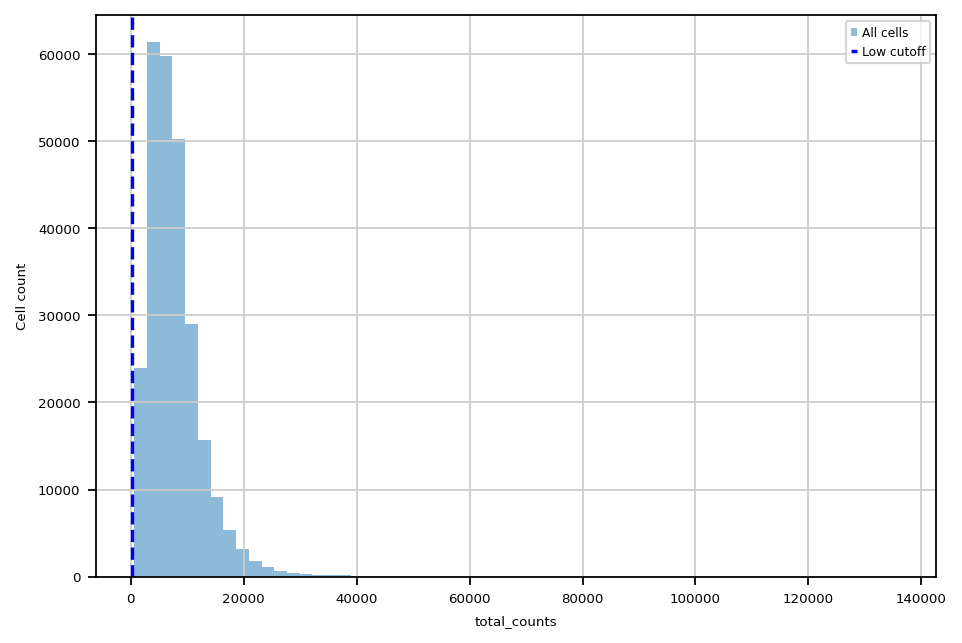


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 0 cells

Filtered cells:


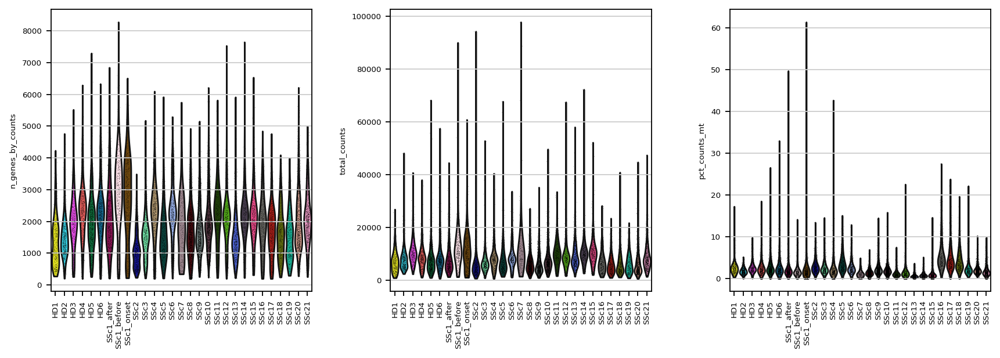

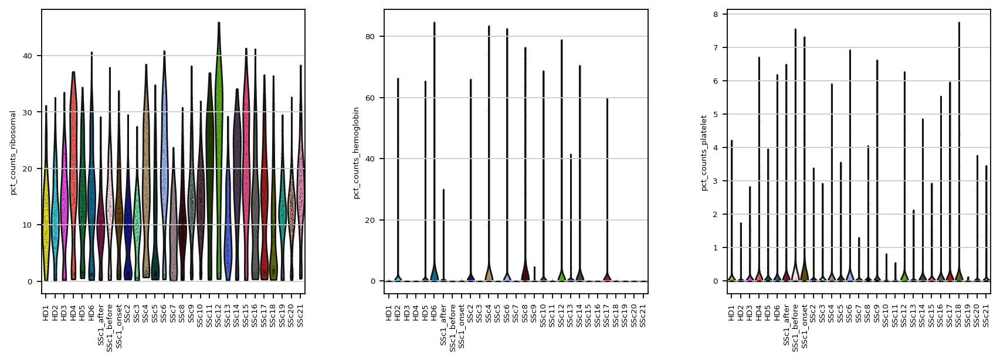


Removed cells:


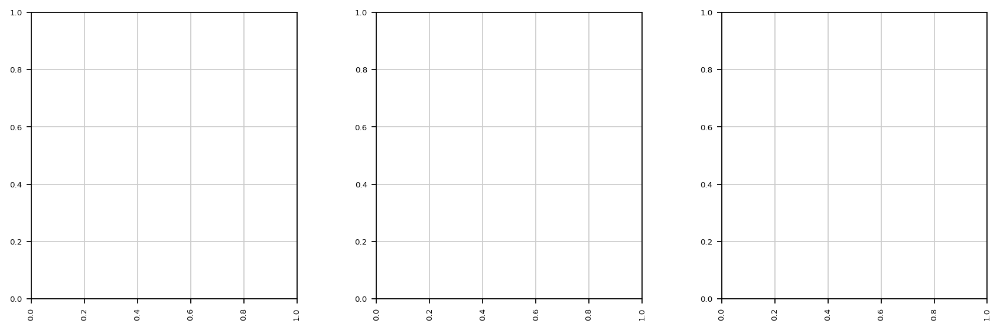

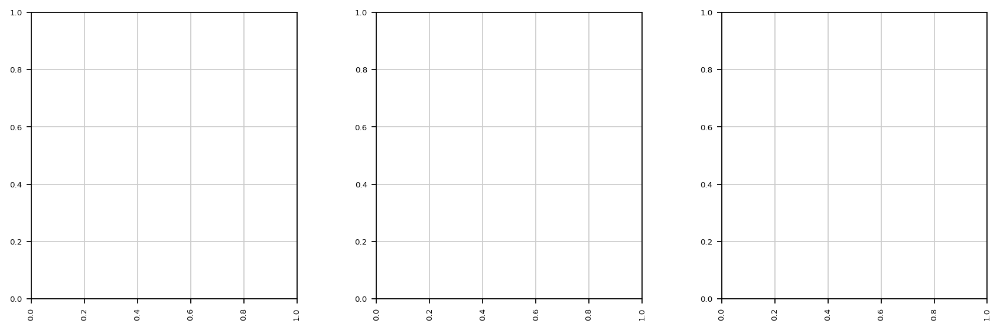

In [21]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    low_base=200,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [22]:
adata
values = adata.obs["total_counts"].dropna()
low_perc = np.percentile(values, 100 - 1)
print(low_perc)

25482.062


In [23]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "total_counts",
    tail_trim: float = 1,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_cutoff = np.percentile(values, 100 - tail_trim)
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 263348
  • Percentile baseline (low): 1%
  • Cells kept: 260714
  • Cells removed: 2634


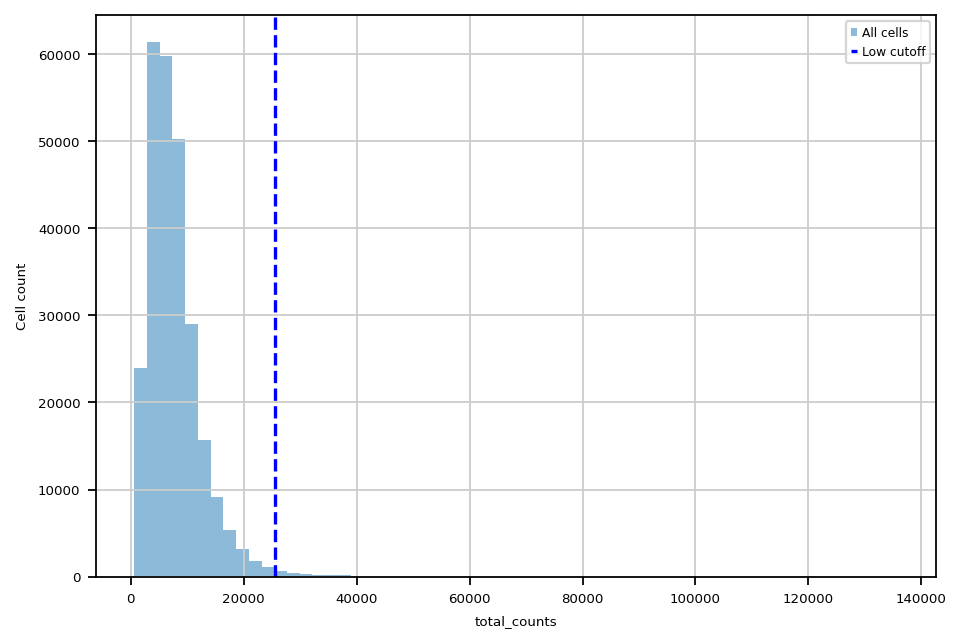


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 2634 cells

Filtered cells:


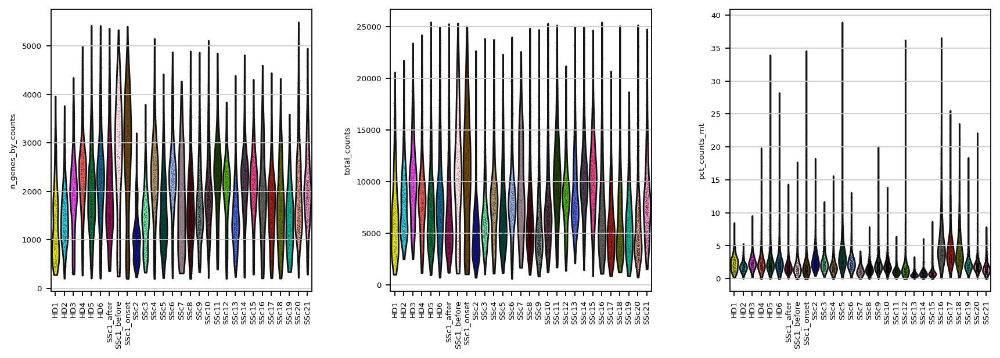

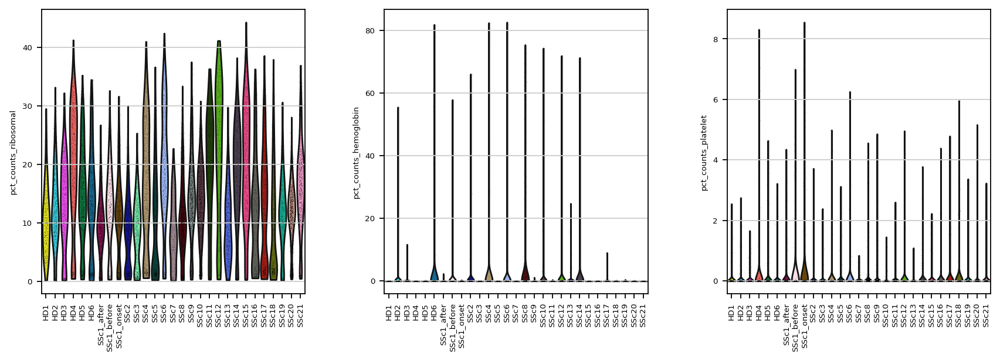


Removed cells:


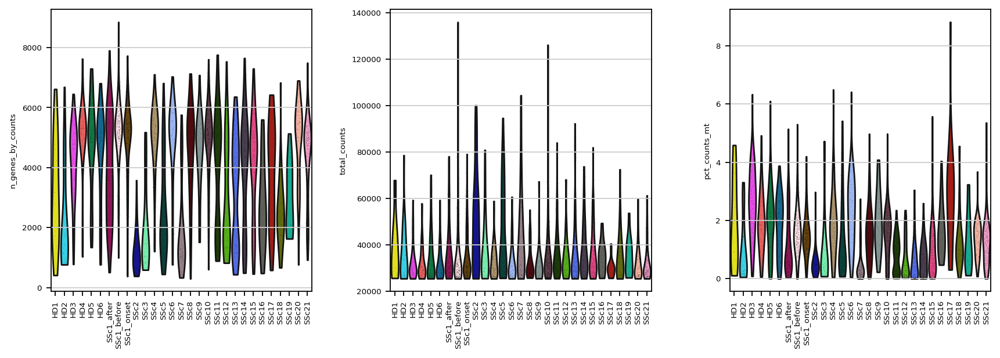

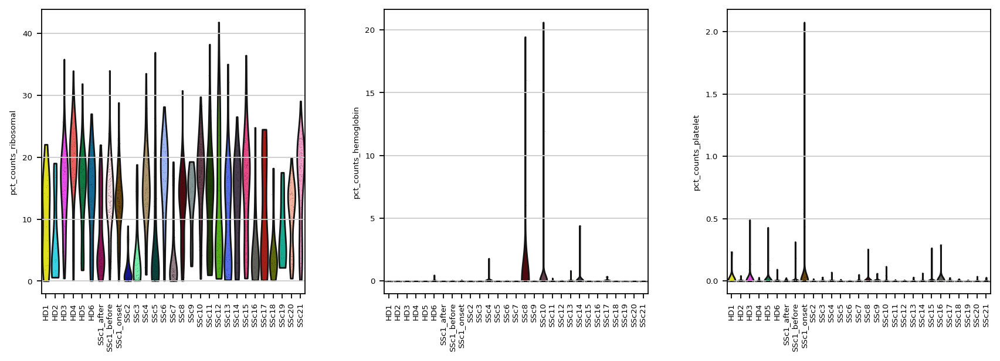

In [24]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="total_counts",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


Adaptive gene filtering summary:
  • Initial number of cells: 260714
  • Percentile baseline (low): 1%
  • Cells kept: 258110
  • Cells removed: 2604


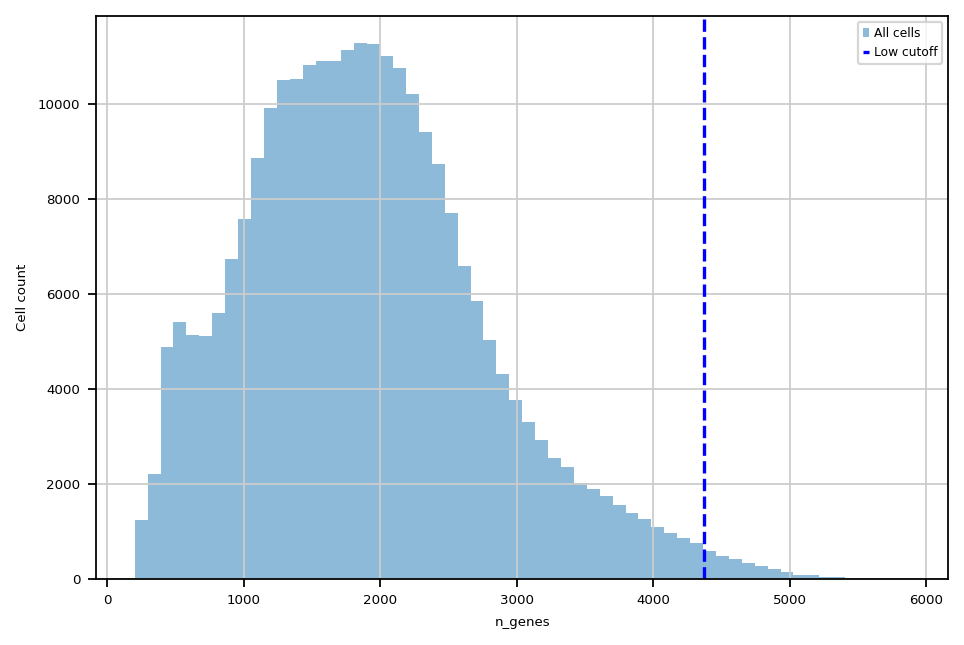


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 2604 cells

Filtered cells:


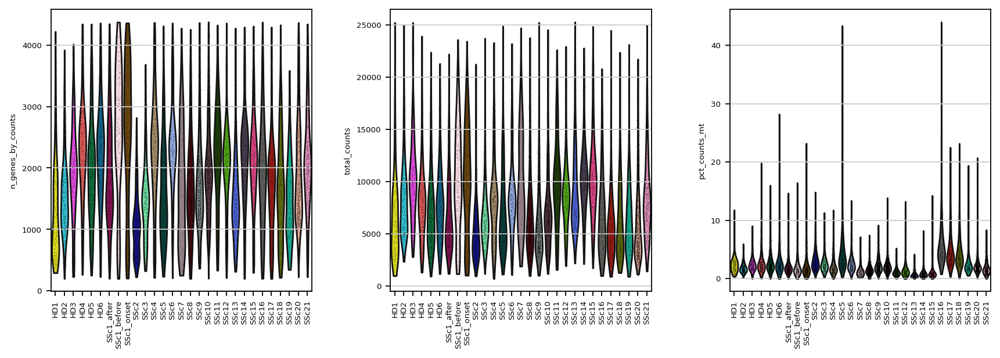

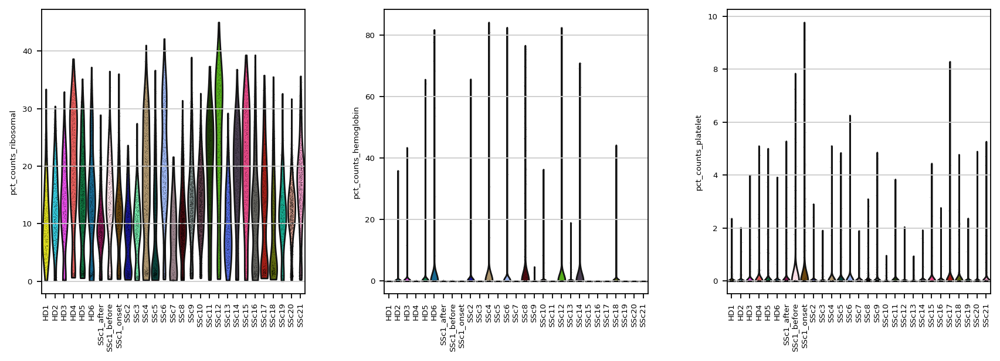


Removed cells:


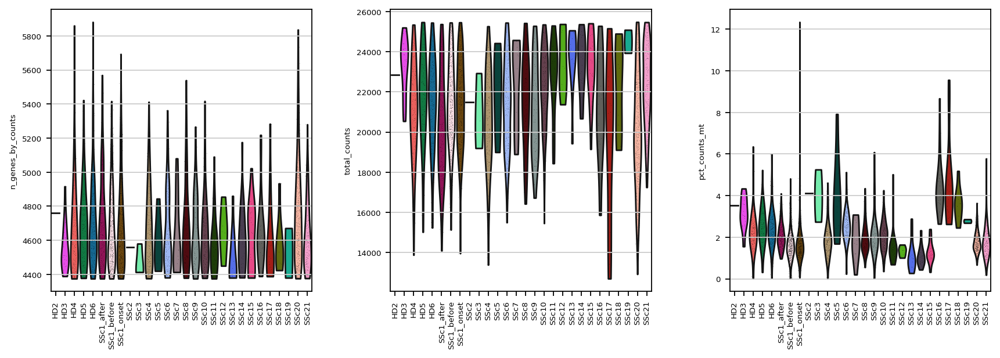

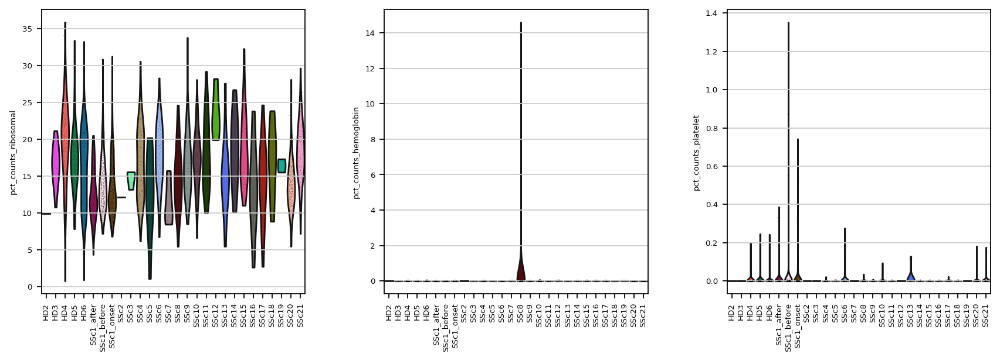

In [25]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="n_genes",
    tail_trim=1,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)

In [26]:
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

def adaptive_gene_filter(
    adata,
    feature: str = "pct_counts_mt",
    low_base: float = 20,
    tail_trim: float = 5,
    plot_hist: bool = True,
    plot_violin: bool = True,
    violin_max_cells: int = 20000
):
    """
    Adaptive filtering based on number of genes per cell (n_genes_by_counts).
    Removes cells with too few detected genes, using percentile and dynamic thresholds.
    Keeps same plotting/violin logic as adaptive_ribo_filter().
    """

    values = adata.obs[feature].dropna()

    # --- Compute baseline (percentile and fraction below threshold) ---
    low_perc = np.percentile(values, 100 - tail_trim)

    if low_perc < low_base:
        low_cutoff = low_base
    else:
        low_cutoff = low_perc
    

    print(f"Adaptive gene filtering summary:")
    print(f"  • Initial number of cells: {adata.n_obs}")
    print(f"  • Percentile baseline (low): {tail_trim}%")
    print(f"  • Percentile threshold: {low_perc}%")
    print(f"  • Chosen threshold: {low_cutoff}%")

    # --- Apply filtering ---
    mask = adata.obs[feature] <= low_cutoff
    adata_filtered = adata[mask].copy()
    adata_removed = adata[~mask].copy()

    print(f"  • Cells kept: {adata_filtered.n_obs}")
    print(f"  • Cells removed: {adata_removed.n_obs}")

    # --- Histogram ---
    if plot_hist:
        plt.figure(figsize=(6,4))
        plt.hist(values, bins=60, alpha=0.5, label='All cells')
        plt.axvline(low_cutoff, color='b', linestyle='--', label='Low cutoff')
        plt.xlabel(feature)
        plt.ylabel("Cell count")
        plt.legend()
        plt.tight_layout()
        plt.show()

    # --- Memory-efficient violin plots (same as ribosomal filter) ---
    if plot_violin:
        def _subsample(adata_in):
            if adata_in.n_obs > violin_max_cells:
                idx = np.random.choice(adata_in.n_obs, violin_max_cells, replace=False)
                return adata_in[idx, :].copy()
            return adata_in

        adata_filt_sub = _subsample(adata_filtered)
        adata_rem_sub = _subsample(adata_removed)

        print(f"\nGenerating violin plots (subsampled):")
        print(f"  Filtered: {adata_filt_sub.n_obs} cells, Removed: {adata_rem_sub.n_obs} cells")

        # Filtered cells
        print("\nFiltered cells:")
        sc.pl.violin(
            adata_filt_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_filt_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

        # Removed cells
        print("\nRemoved cells:")
        sc.pl.violin(
            adata_rem_sub,
            ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )
        sc.pl.violin(
            adata_rem_sub,
            ["pct_counts_ribosomal", "pct_counts_hemoglobin", "pct_counts_platelet"],
            groupby="sample",
            jitter=0.2,
            rotation=90,
            multi_panel=True,
            size=0.2,
            show=True
        )

    return adata_filtered, adata_removed


Adaptive gene filtering summary:
  • Initial number of cells: 258110
  • Percentile baseline (low): 5%
  • Percentile threshold: 5.545268692076205%
  • Chosen threshold: 20%
  • Cells kept: 257846
  • Cells removed: 264


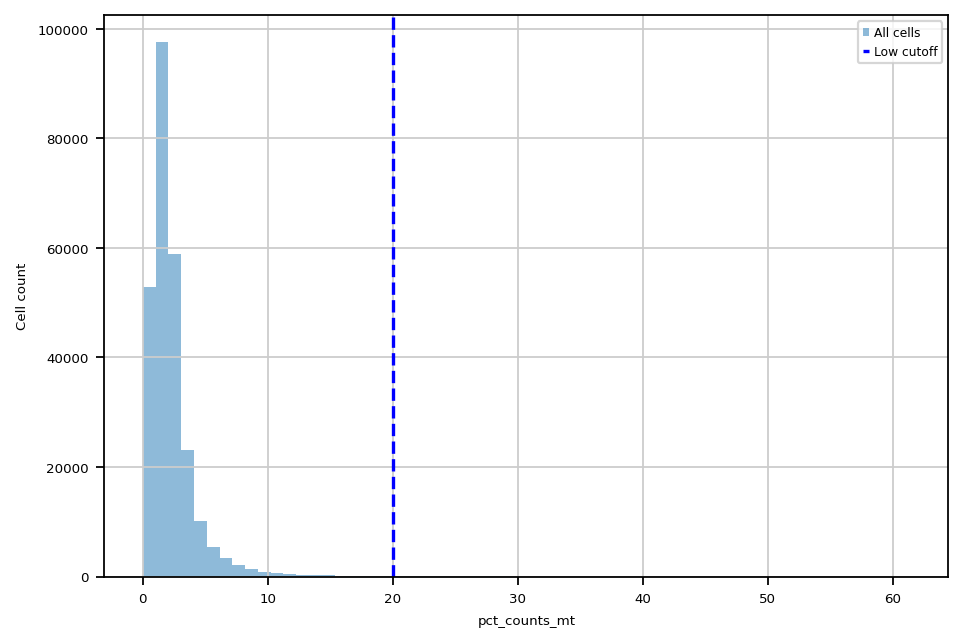


Generating violin plots (subsampled):
  Filtered: 20000 cells, Removed: 264 cells

Filtered cells:


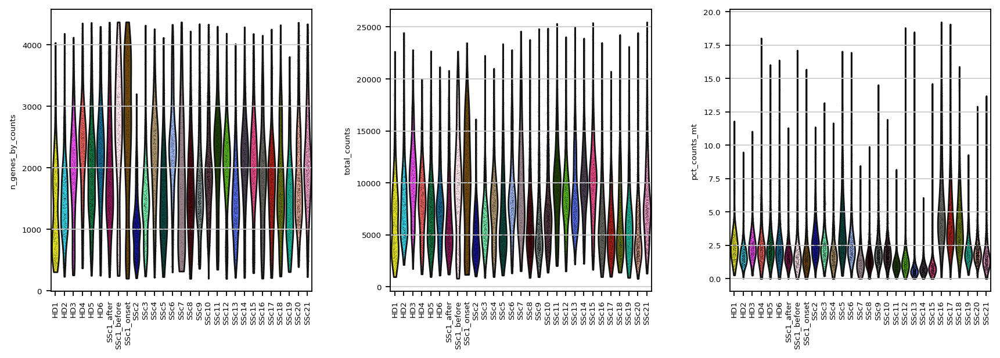

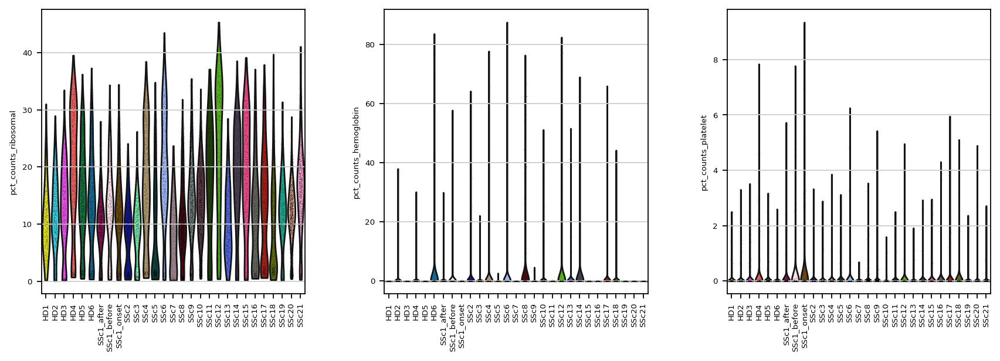


Removed cells:


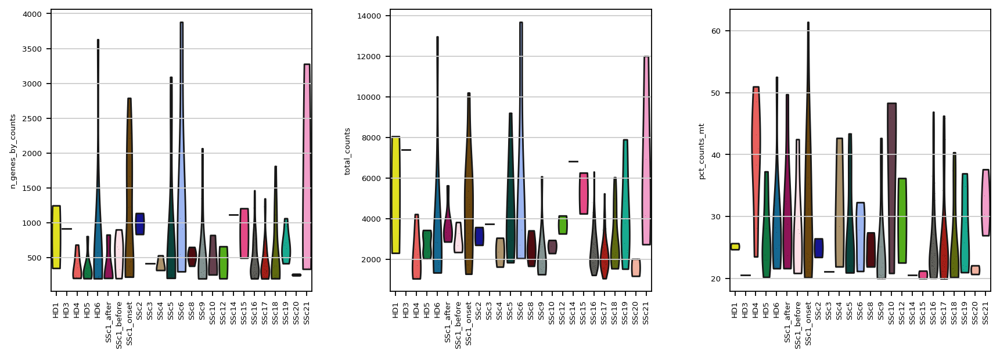

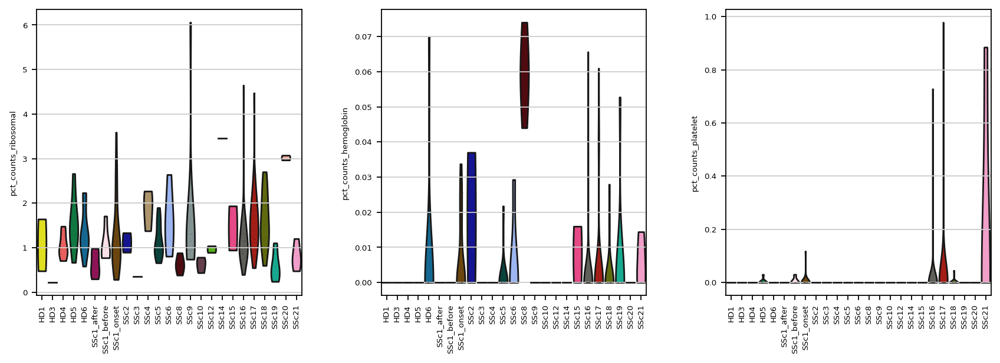

In [27]:
adata_merged, adata_gene_removed = adaptive_gene_filter(
    adata_merged,
    feature="pct_counts_mt",
    low_base=20,
    tail_trim=5,
    plot_hist=True,
    plot_violin=True,
    violin_max_cells=20000
)


In [28]:
import scanpy as sc
import numpy as np

print(f"Genes before: {adata_merged.n_vars}")

# Calcola il totale delle reads per gene (somma su tutte le cellule)
gene_counts = np.array(adata_merged.X.sum(axis=0)).flatten()

# Crea una maschera booleana: True per i geni con >= 10 reads
gene_mask = gene_counts >= 10

# Filtra l'AnnData
adata_merged = adata_merged[:, gene_mask].copy()

print(f"Genes after: {adata_merged.n_vars}")

Genes before: 36648
Genes after: 25973


# After Filtering and clustering

In [29]:
adata_merged.raw = adata_merged.copy()
sc.pp.normalize_total(adata_merged, target_sum=1e4)
print(adata_merged.raw.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 483983317 stored elements and shape (257846, 25973)>
  Coords	Values
  (0, 17)	1.0
  (0, 29)	1.0
  (0, 47)	1.0
  (0, 54)	1.0
  (0, 66)	2.0
  (0, 103)	1.0
  (0, 122)	1.0
  (0, 124)	1.0
  (0, 174)	1.0
  (0, 185)	1.0
  (0, 207)	2.0
  (0, 248)	1.0
  (0, 255)	2.0
  (0, 271)	1.0
  (0, 280)	1.0
  (0, 299)	1.0
  (0, 332)	1.0
  (0, 335)	1.0
  (0, 371)	3.0
  (0, 402)	1.0
  (0, 408)	1.0
  (0, 410)	1.0
  (0, 428)	1.0
  (0, 430)	1.0
  (0, 439)	1.0
  :	:
  (257845, 25946)	45.0
  (257845, 25947)	21.0
  (257845, 25948)	3.0
  (257845, 25949)	9.0
  (257845, 25950)	14.0
  (257845, 25951)	26.0
  (257845, 25952)	11.0
  (257845, 25953)	6.0
  (257845, 25954)	169.0
  (257845, 25955)	7.0
  (257845, 25956)	3.0
  (257845, 25957)	266.0
  (257845, 25958)	36.0
  (257845, 25959)	79.0
  (257845, 25960)	364.0
  (257845, 25961)	16.0
  (257845, 25962)	13.0
  (257845, 25963)	63.0
  (257845, 25964)	14.0
  (257845, 25965)	4.0
  (257845, 25966)	26.0
  (257845, 25

In [30]:
import re

print(f"Original genes: {adata_merged.n_vars}")

# Keep genes that do NOT match the pattern: ends with .digit
pattern = re.compile(r".*\.\d+$")
keep_genes = [not pattern.match(gene) for gene in adata_merged.var_names]

# Subset the AnnData object
adata2 = adata_merged[:, keep_genes].copy()

print(f"Filtered genes: {adata2.n_vars}")

Original genes: 25973
Filtered genes: 19142


In [31]:
cite_genes = adata.var_names[adata.var_names.str.contains("CITE", case=False, na=False)]
print(cite_genes)

Index(['CITED4', 'CITED2', 'CITED1'], dtype='object')


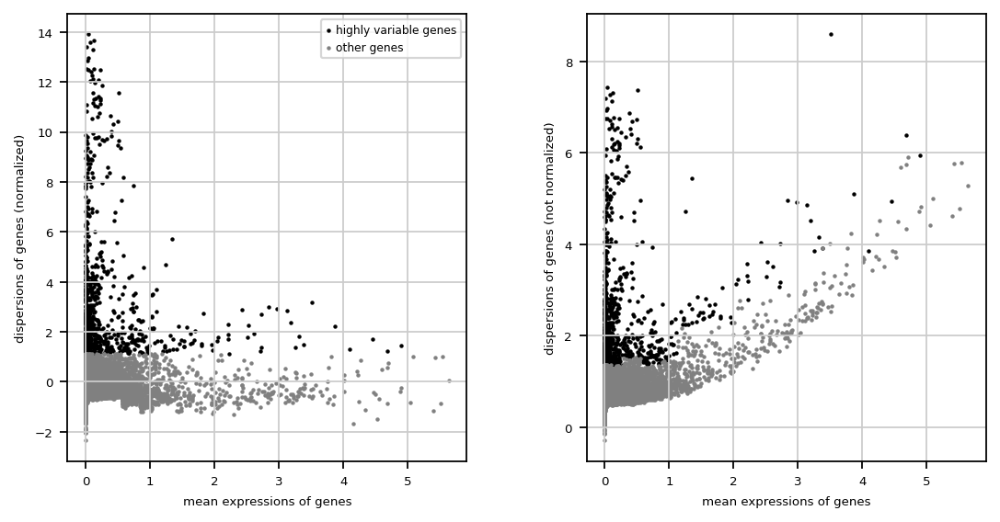

In [32]:
sc.pp.log1p(adata2)
sc.pp.highly_variable_genes(adata2, n_top_genes=1000)
#sc.pp.highly_variable_genes(adata2, min_mean=0.0125, max_mean=3, min_disp=0.5, n_top_genes=1000)
sc.pl.highly_variable_genes(adata2)

In [33]:
hv_genes = adata2.var.highly_variable
print(hv_genes)
adata_hv = adata2[:, hv_genes].copy()

LINC01409    False
FAM87B       False
LINC01128    False
LINC00115    False
FAM41C       False
             ...  
IgG          False
CD21          True
PD-1         False
CD15         False
CD22-1       False
Name: highly_variable, Length: 19142, dtype: bool


In [34]:
import numpy as np
import skimage

# Run Scrublet
sc.pp.scrublet(adata_hv, use_approx_neighbors=True, sim_doublet_ratio=1, n_neighbors=10, n_prin_comps=5 )

print("predicted doublets")
print(adata_hv.obs['predicted_doublet'].sum())  # conta i True direttamente

predicted doublets
5278


cell
HD5_AAACCTGAGCTATGCT-1-E-GEAD-872            0.002500
HD5_AAACCTGAGTAGGTGC-1-E-GEAD-872            0.035156
HD5_AAACCTGCAAATCCGT-1-E-GEAD-872            0.023973
HD5_AAACCTGCACATCCGG-1-E-GEAD-872            0.002500
HD5_AAACCTGCACCAGGCT-1-E-GEAD-872            0.050000
                                               ...   
SSc1_before_TTTGTCAGTAATCACC-1-E-GEAD-872    0.015244
SSc1_before_TTTGTCAGTAGAAGGA-1-E-GEAD-872    0.005236
SSc1_before_TTTGTCATCATATCGG-1-E-GEAD-872    0.011561
SSc1_before_TTTGTCATCTCAAACG-1-E-GEAD-872    0.042017
SSc1_before_TTTGTCATCTGTCCGT-1-E-GEAD-872    0.002500
Name: doublet_score, Length: 257846, dtype: float64
cell
HD5_AAACCTGAGCTATGCT-1-E-GEAD-872            False
HD5_AAACCTGAGTAGGTGC-1-E-GEAD-872            False
HD5_AAACCTGCAAATCCGT-1-E-GEAD-872            False
HD5_AAACCTGCACATCCGG-1-E-GEAD-872            False
HD5_AAACCTGCACCAGGCT-1-E-GEAD-872            False
                                             ...  
SSc1_before_TTTGTCAGTAATCACC-1-E-GEAD-

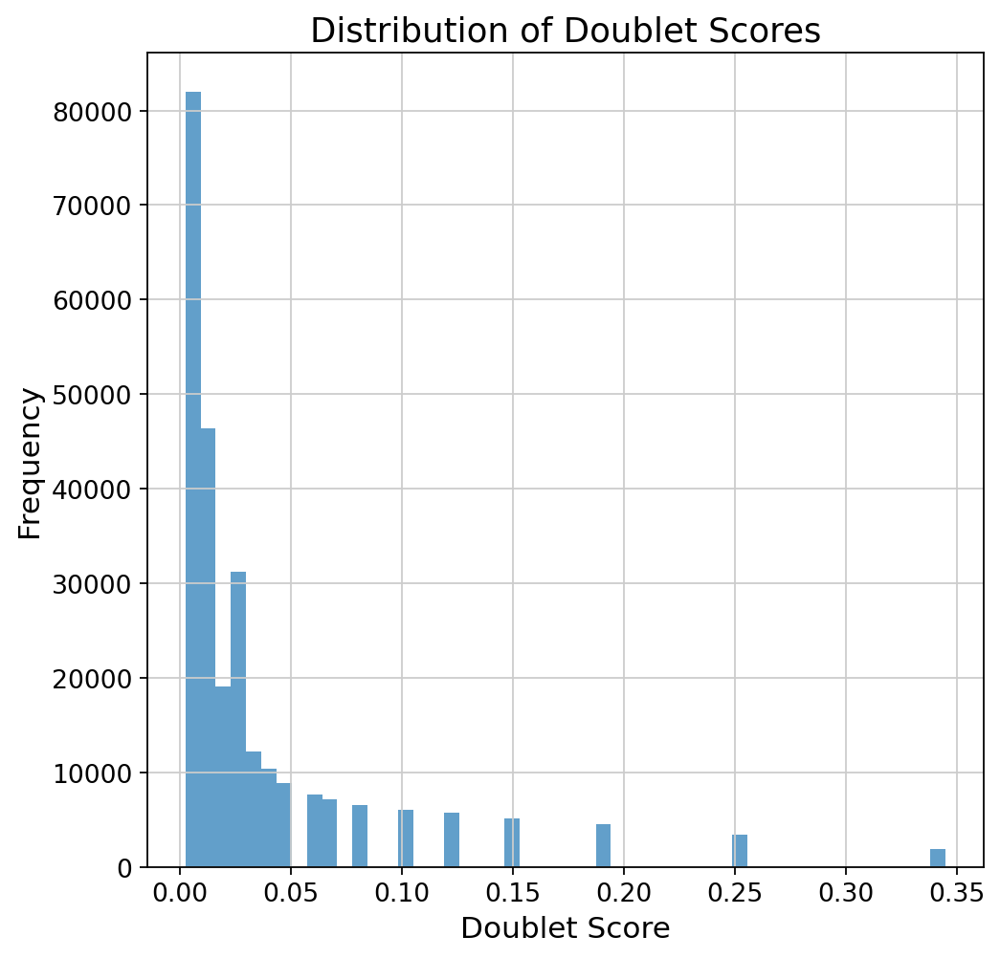

In [35]:
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size

# Scrublet results are stored in the AnnData object
# Doublet scores
print(adata_hv.obs['doublet_score'])
# Predicted doublets
print(adata_hv.obs['predicted_doublet'])

# Histogram of doublet scores
adata_hv.obs['doublet_score'].plot.hist(bins=50, alpha=0.7)
plt.xlabel('Doublet Score')
plt.ylabel('Frequency')
plt.title('Distribution of Doublet Scores')
plt.show()

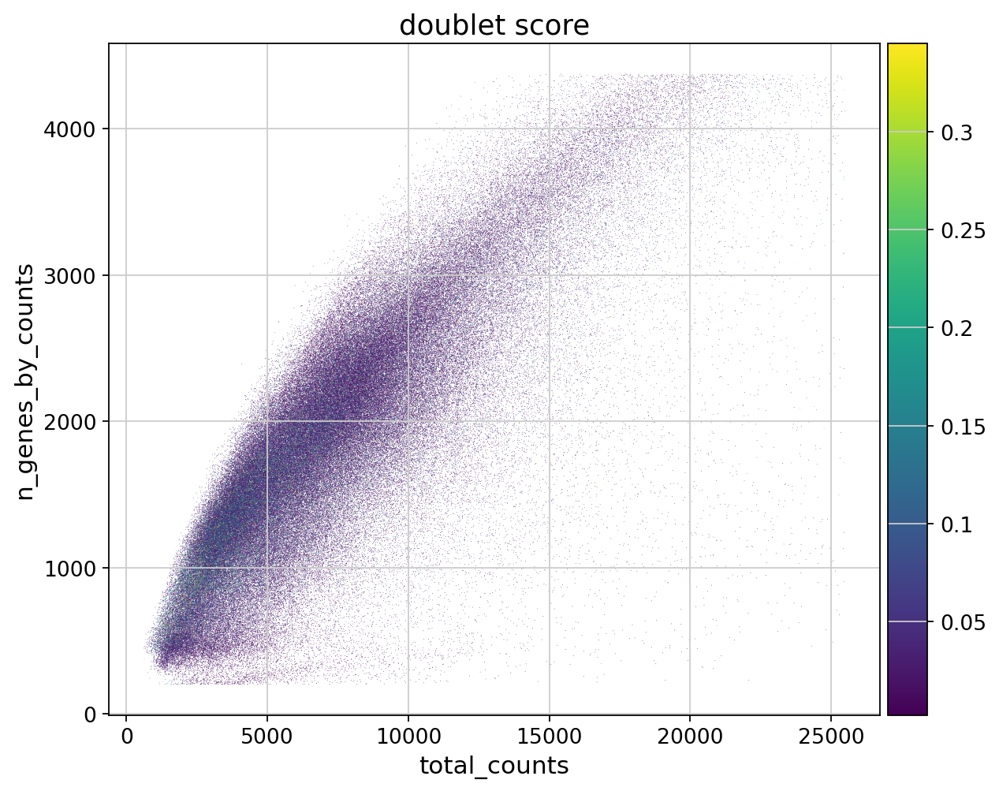

In [36]:
plt.rcParams["figure.figsize"] = (7, 7)
plt.rcParams["axes.titlesize"] = 16       # Title size
plt.rcParams["axes.labelsize"] = 14       # X and Y label size
plt.rcParams["xtick.labelsize"] = 12      # X tick size
plt.rcParams["ytick.labelsize"] = 12      # Y tick size
sc.pl.scatter(adata_hv, x="total_counts", y="n_genes_by_counts", color="doublet_score")

In [37]:
adata_hv.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].fillna(False).astype(int)  # 1 = doublet, 0 = singlet

In [38]:
adata3 = adata2
adata3.obs['predicted_doublet'] = adata_hv.obs['predicted_doublet'].copy()
adata3.obs['doublet_score'] = adata_hv.obs['doublet_score'].copy()

print("Number of cells")
print(len(adata3.obs))

Number of cells
257846


In [39]:
adata_removed = adata3[adata3.obs["predicted_doublet"] == 1].copy()
adata3 = adata3[adata3.obs["predicted_doublet"] == 0].copy()

print("Number of cells post doublets")
print(len(adata3.obs))

Number of cells post doublets
252568


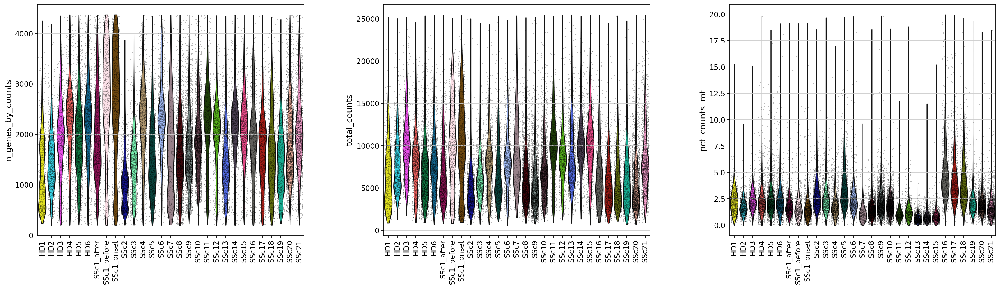

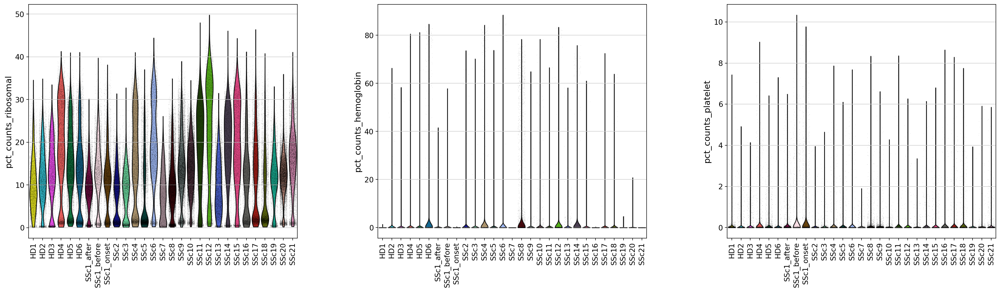

In [40]:
sc.pl.violin(adata3,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata3,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

Cells removed
5278


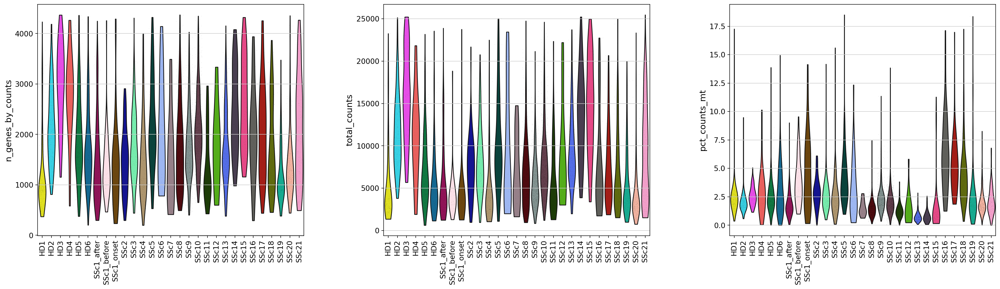

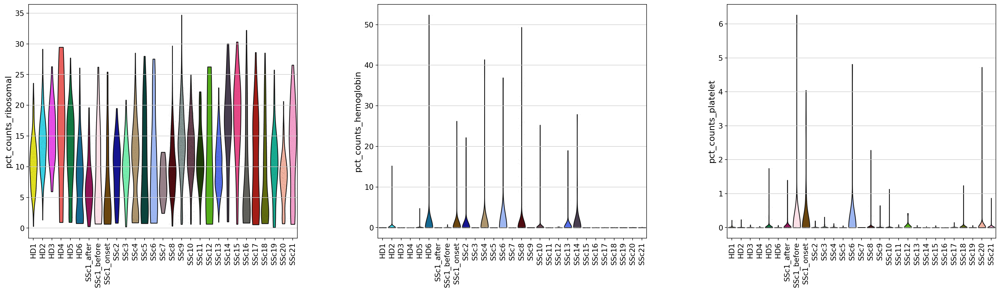

In [41]:
print("Cells removed")
print(len(adata_removed.obs))
sc.pl.violin(adata_removed,
    ["n_genes_by_counts", "total_counts","pct_counts_mt"],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)
sc.pl.violin(adata_removed,
    ["pct_counts_ribosomal","pct_counts_hemoglobin","pct_counts_platelet" ],
    groupby='sample',
    jitter=0.4,
    rotation = 90,
    multi_panel=True,
    size = 0.2)

In [42]:
print("Average number of cells per sample")
print(len(adata3.obs)/adata3.obs["sample"].nunique())

Average number of cells per sample
8709.241379310344


In [43]:
adata3.obs["sample"].nunique()

29

In [44]:
## Scale data
#sc.pp.scale(adata3, max_value=10)
## 

sc.tl.pca(adata3, svd_solver="arpack", use_highly_variable=True)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/scanpy/preprocessing/_pca/__init__.py:227: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  mask_var_param, mask_var = _handle_mask_var(


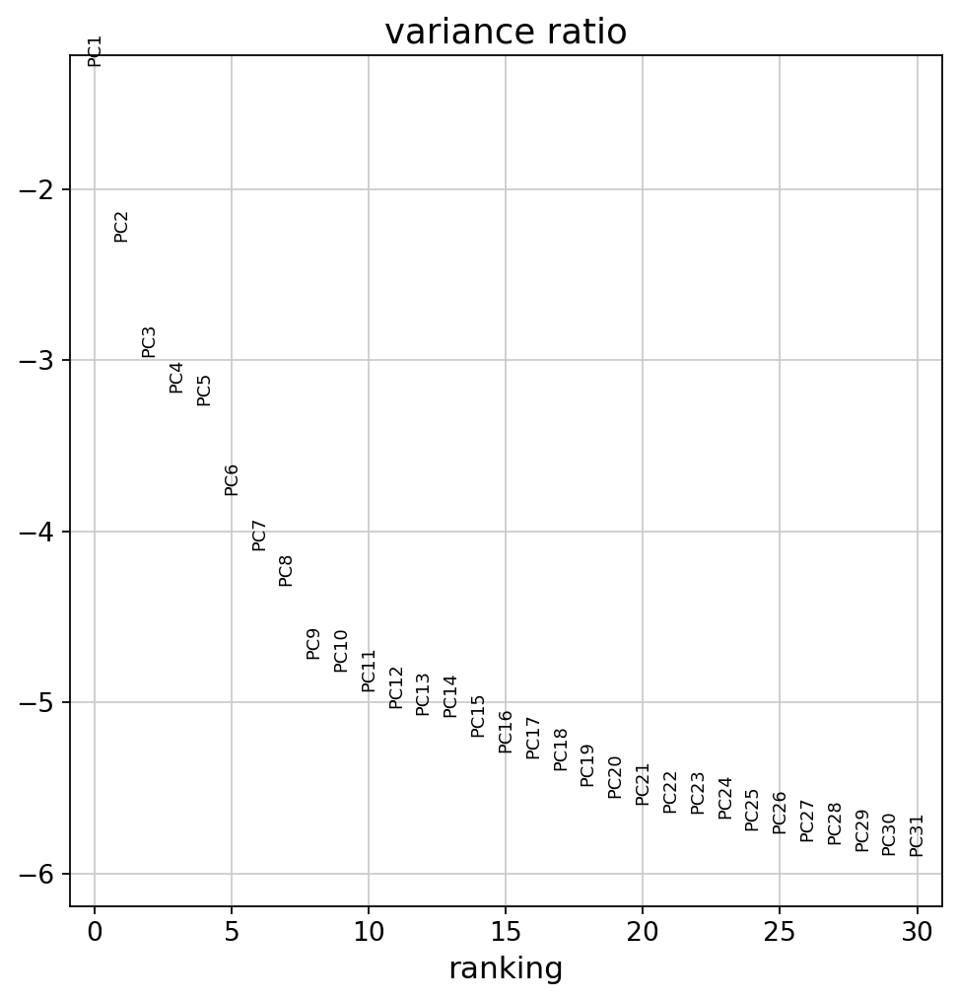

In [45]:
sc.pl.pca_variance_ratio(adata3, log=True)

In [47]:
sc.pp.neighbors(adata3, n_neighbors=15, n_pcs=50)

/home/ciperi/data/conda/envs/Atlas_SSC/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [48]:
sc.tl.umap(adata3)

In [49]:
adata3.obs

,n_genes,sample,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribosomal,pct_counts_hemoglobin,pct_counts_platelet,umi_gene_ratio,batch,...,Comment[SRA_EXPERIMENT],Comment[SRA_RUN],Technology_Type,Array_Data_File,Protocol_REF.4,Derived_Array_Data_File,Factor_Value[disease],dataset,predicted_doublet,doublet_score
cell,,,,,,,,,,,,,,,,,,,,,
HD5_AAACCTGAGCTATGCT-1-E-GEAD-872,1612,HD5,5384.0,1612,6.240713,1.411590,0.000000,0.000000,3.339950,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.002500
HD5_AAACCTGAGTAGGTGC-1-E-GEAD-872,1619,HD5,4838.0,1619,1.054155,13.290615,0.000000,0.000000,2.988264,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.035156
HD5_AAACCTGCAAATCCGT-1-E-GEAD-872,1808,HD5,4460.0,1808,2.174888,16.053812,0.000000,0.000000,2.466814,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.023973
HD5_AAACCTGCACATCCGG-1-E-GEAD-872,583,HD5,2108.0,583,5.075901,2.561670,0.000000,0.000000,3.615780,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.002500
HD5_AAACCTGCACCAGGCT-1-E-GEAD-872,1724,HD5,10381.0,1724,0.587612,9.748579,0.000000,0.009633,6.021462,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.050000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SSc1_before_TTTGTCAGTAATCACC-1-E-GEAD-872,1706,SSc1_before,4763.0,1706,6.928407,3.611169,0.000000,0.000000,2.791911,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.015244
SSc1_before_TTTGTCAGTAGAAGGA-1-E-GEAD-872,2381,SSc1_before,7432.0,2381,1.735737,12.405813,0.000000,0.000000,3.121378,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.005236
SSc1_before_TTTGTCATCATATCGG-1-E-GEAD-872,2840,SSc1_before,10471.0,2840,1.852736,16.426320,0.009550,0.000000,3.686972,E-GEAD-872,...,nan,nan,nan,nan,nan,nan,NaN,E-GEAD-872,0,0.011561


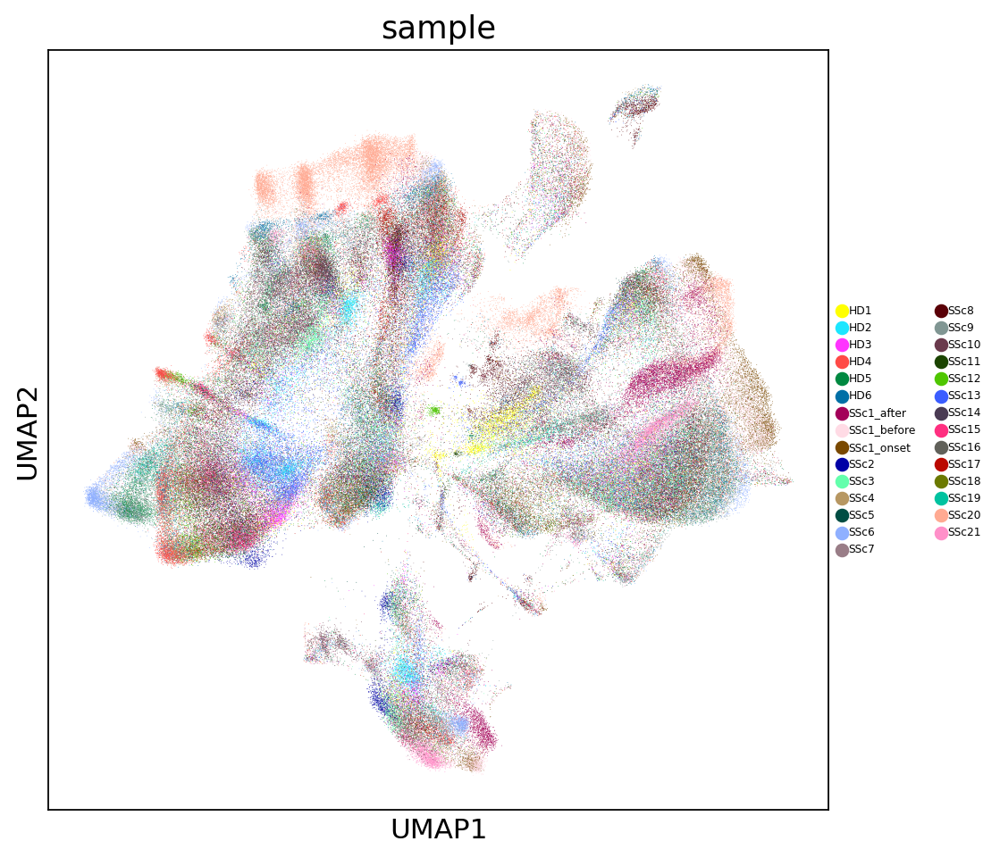

In [50]:
sc.pl.umap(adata3, color=['sample'])

In [51]:
# Loop over each unique batch and generate a UMAP plot
for batch in adata3.obs['sample'].unique():
    print(batch)
    # Create a new adata object for the specific batch
    adata_batch = adata3[adata3.obs['sample'] == batch]
    
    # Plot UMAP for this batch
    #sc.pl.umap(adata_batch, color='sample', title=f"UMAP for {batch}")

HD5
SSc9
SSc14
SSc4
SSc1_onset
SSc8
SSc12
SSc19
SSc2
SSc11
SSc16
SSc15
SSc20
HD6
SSc5
HD2
SSc1_after
SSc21
HD3
SSc18
SSc7
HD1
SSc17
HD4
SSc13
SSc10
SSc3
SSc6
SSc1_before


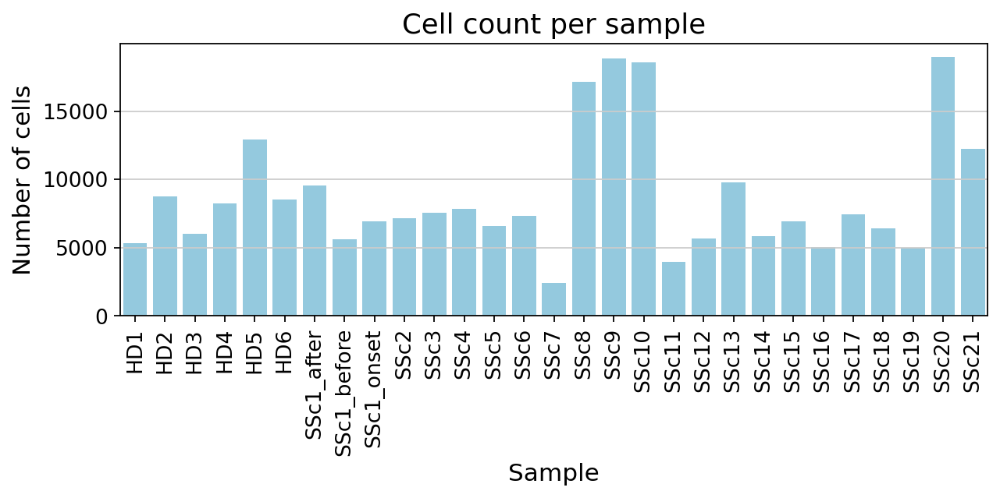

In [52]:
#Check and removal samples with less than 200 cells
import matplotlib.pyplot as plt
import seaborn as sns

# Count number of cells per sample
cell_counts = adata3.obs['sample'].value_counts().sort_index()

# Plot
plt.figure(figsize=(8,4))
sns.barplot(x=cell_counts.index, y=cell_counts.values, color="skyblue")
plt.xticks(rotation=90)
plt.ylabel("Number of cells")
plt.xlabel("Sample")
plt.title("Cell count per sample")
plt.tight_layout()
plt.show()


In [53]:
# Define minimum cell count threshold
#min_cells = 500

# Identify samples that meet the threshold
#valid_samples = cell_counts[cell_counts >= min_cells].index

# Filter the AnnData object
#adata3 = adata3[adata3.obs['sample'].isin(valid_samples)].copy()

#print(f"Kept {len(valid_samples)} samples with ≥ {min_cells} cells.")
#print(f"Remaining cells: {adata3.n_obs}")


# Annotation and Fibroblast isolation 

In [54]:
import celltypist
import scanpy as sc
from celltypist import models

# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Immune_All_High.pkl')

adata = sc.AnnData(adata3.raw.X.copy(), var=adata3.raw.var.copy(), obs=adata3.obs.copy())
print(adata.X)

<Compressed Sparse Row sparse matrix of dtype 'float32'
	with 474380421 stored elements and shape (252568, 25973)>
  Coords	Values
  (0, 17)	1.0
  (0, 29)	1.0
  (0, 47)	1.0
  (0, 54)	1.0
  (0, 66)	2.0
  (0, 103)	1.0
  (0, 122)	1.0
  (0, 124)	1.0
  (0, 174)	1.0
  (0, 185)	1.0
  (0, 207)	2.0
  (0, 248)	1.0
  (0, 255)	2.0
  (0, 271)	1.0
  (0, 280)	1.0
  (0, 299)	1.0
  (0, 332)	1.0
  (0, 335)	1.0
  (0, 371)	3.0
  (0, 402)	1.0
  (0, 408)	1.0
  (0, 410)	1.0
  (0, 428)	1.0
  (0, 430)	1.0
  (0, 439)	1.0
  :	:
  (252567, 25946)	45.0
  (252567, 25947)	21.0
  (252567, 25948)	3.0
  (252567, 25949)	9.0
  (252567, 25950)	14.0
  (252567, 25951)	26.0
  (252567, 25952)	11.0
  (252567, 25953)	6.0
  (252567, 25954)	169.0
  (252567, 25955)	7.0
  (252567, 25956)	3.0
  (252567, 25957)	266.0
  (252567, 25958)	36.0
  (252567, 25959)	79.0
  (252567, 25960)	364.0
  (252567, 25961)	16.0
  (252567, 25962)	13.0
  (252567, 25963)	63.0
  (252567, 25964)	14.0
  (252567, 25965)	4.0
  (252567, 25966)	26.0
  (252567, 25

In [55]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

🔬 Input data has 252568 cells and 25973 genes
🔗 Matching reference genes in the model
🧬 5972 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


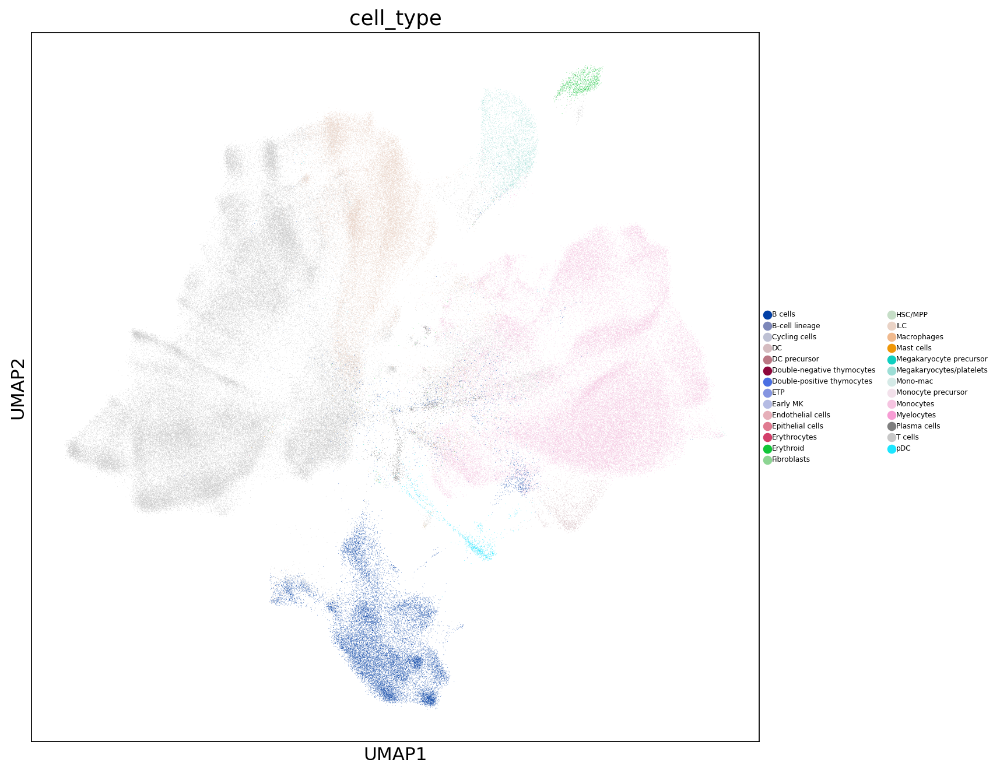

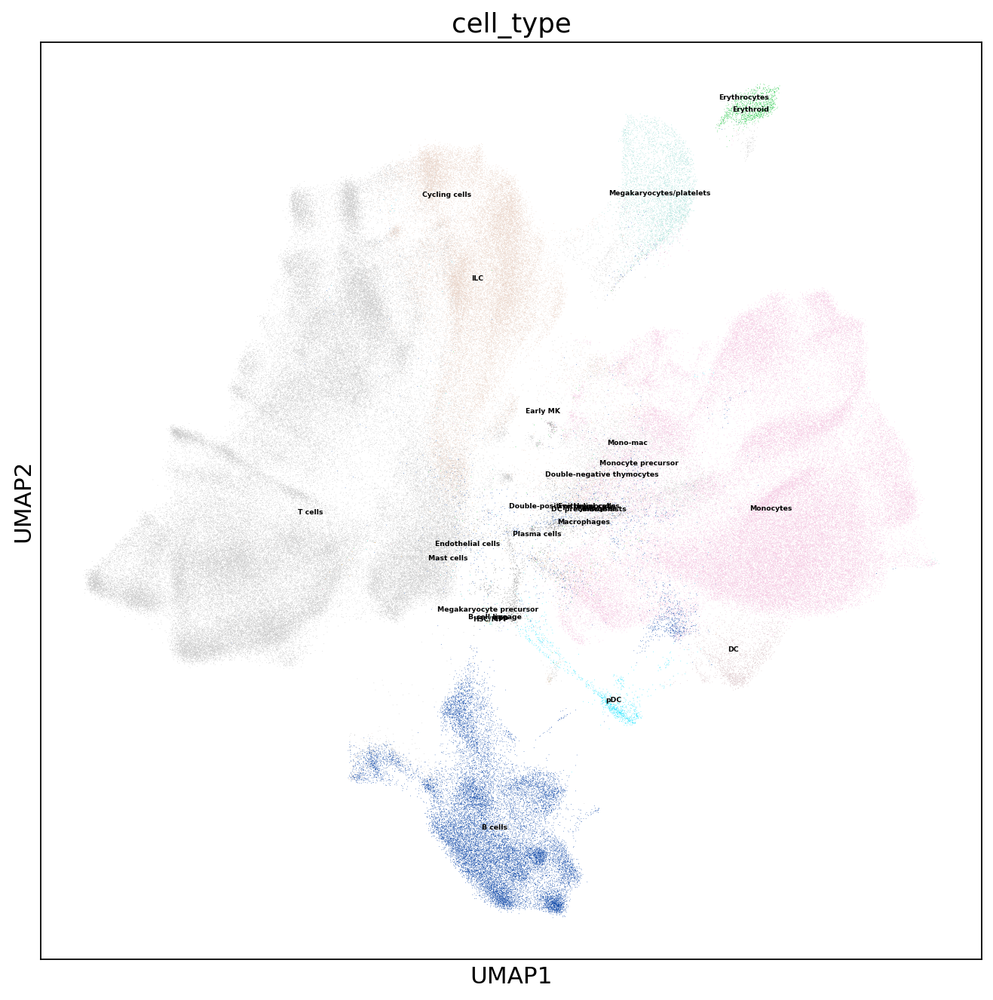

In [56]:
# Predict cell types
predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 12 cell types with ≥ 50 cells
Remaining cells: 252376
Remaining cell types: 12


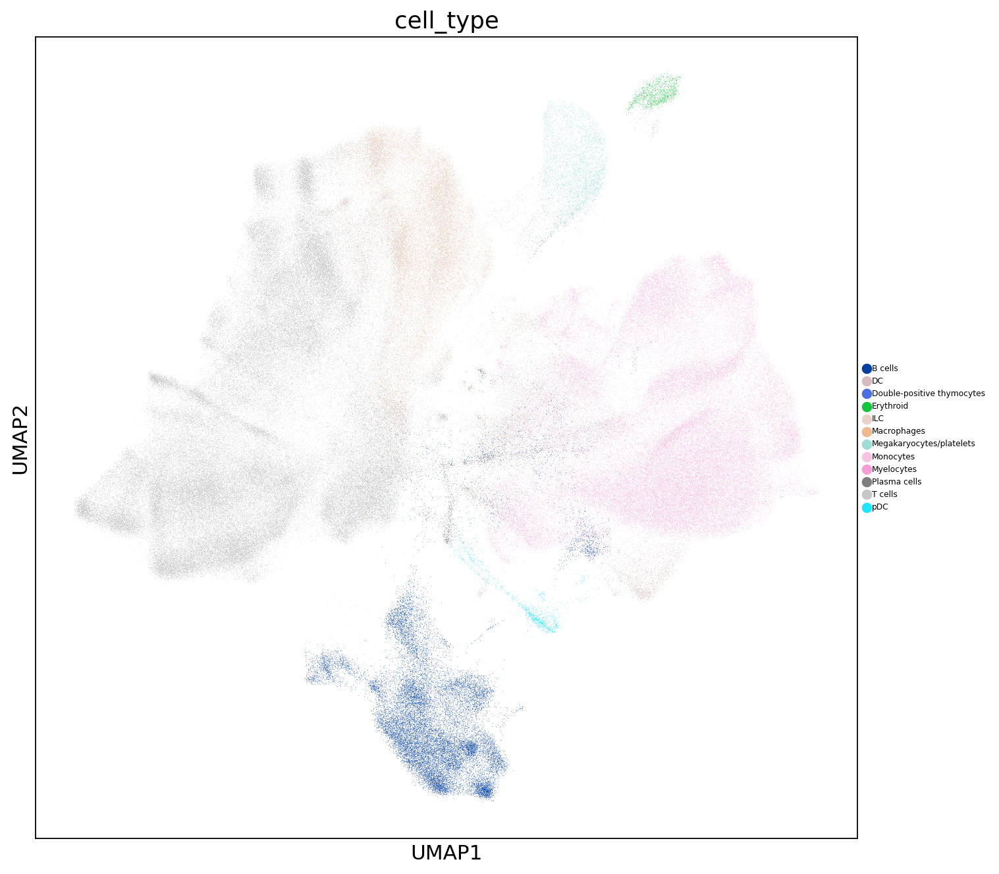

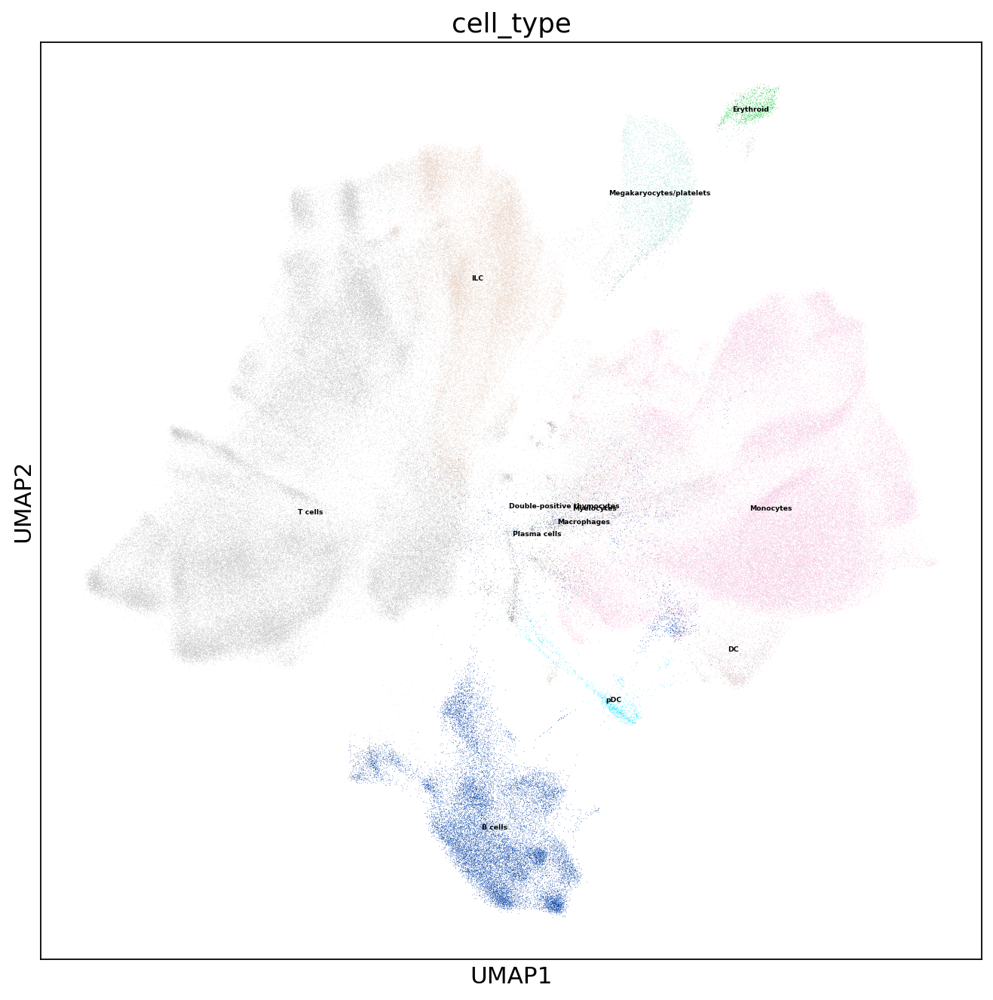

In [57]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type'])

sc.pl.umap(adata3, color=['cell_type'], legend_loc = "on data", legend_fontsize= 'x-small')




In [58]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


B cells              → kept 500 / 23093 cells
DC                   → kept 500 / 2294 cells
Double-positive thymocytes → kept 54 / 54 cells
Erythroid            → kept 500 / 1194 cells
ILC                  → kept 500 / 34487 cells
Macrophages          → kept 500 / 576 cells
Megakaryocytes/platelets → kept 500 / 3828 cells
Monocytes            → kept 500 / 72318 cells
Myelocytes           → kept 144 / 144 cells
Plasma cells         → kept 500 / 1862 cells
T cells              → kept 500 / 111341 cells
pDC                  → kept 500 / 1185 cells

Total cells before: 252376
Total cells after subsampling: 5198


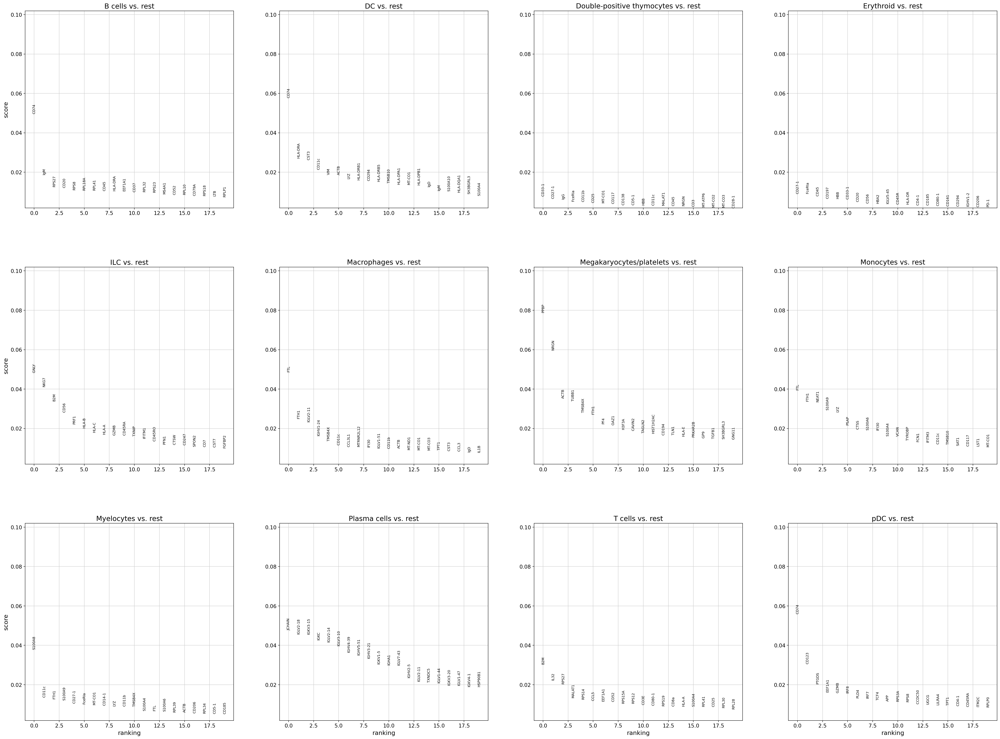

In [59]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

🔬 Input data has 252568 cells and 25973 genes
🔗 Matching reference genes in the model
🧬 5972 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


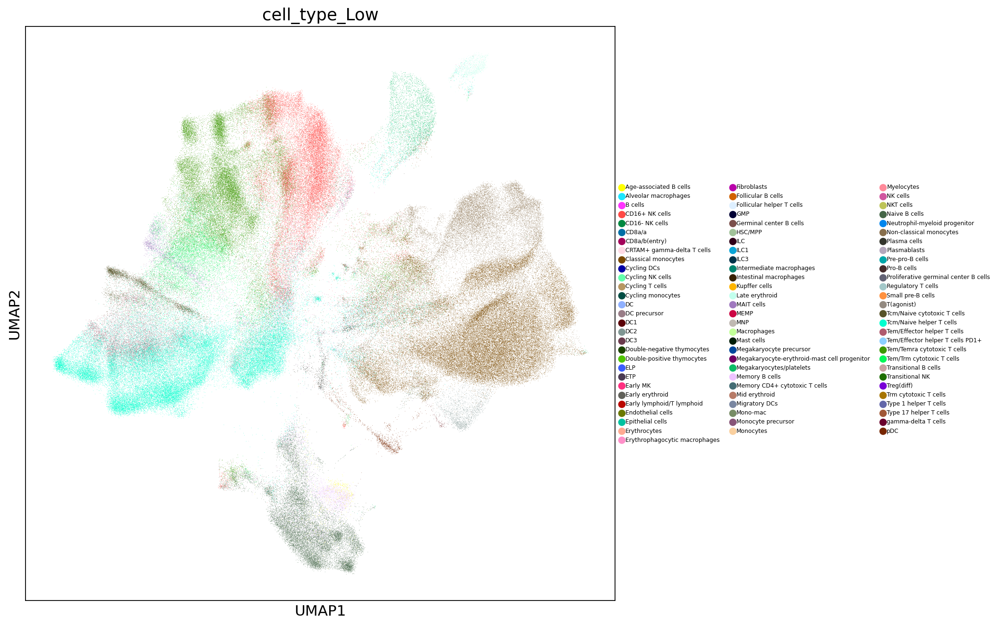

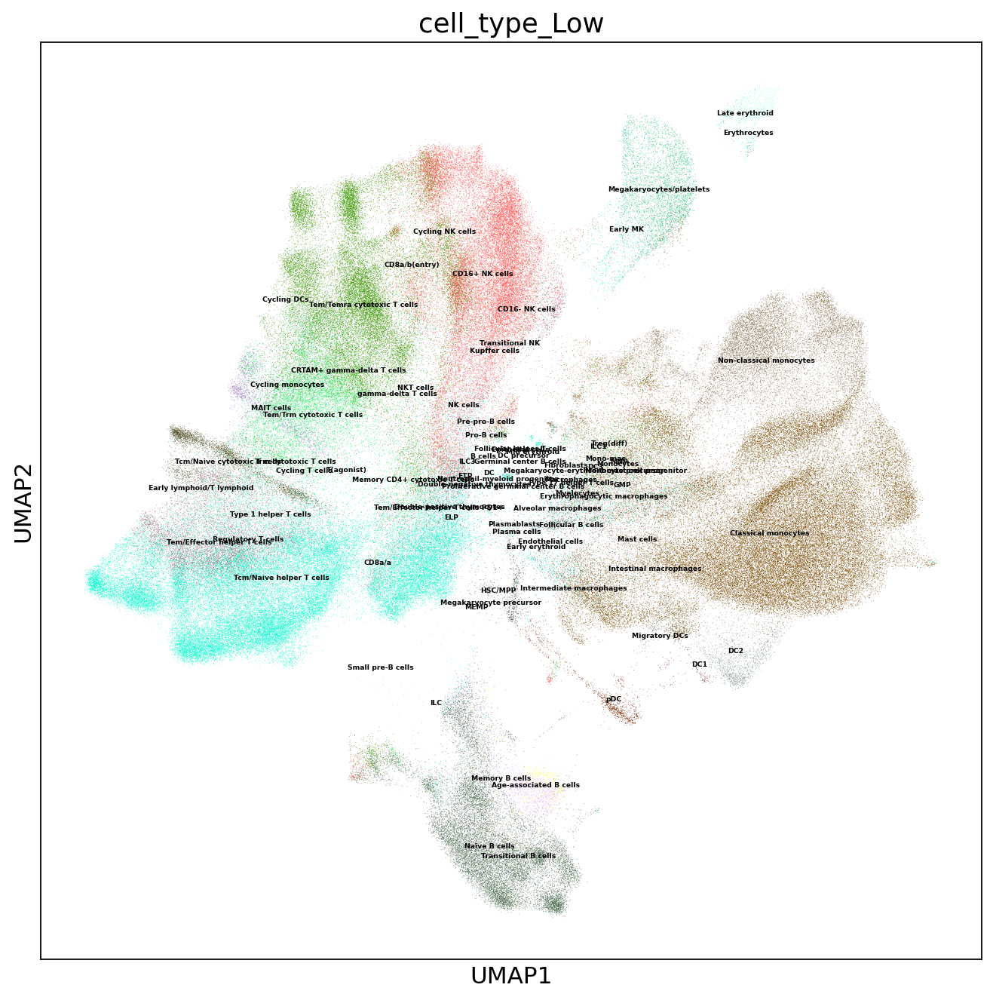

In [60]:
# Download the latest immune cell model
model = celltypist.models.Model.load('/home/ciperi/data/Atlas_SSC/Celltypist_model/Immune_All_Low.pkl')


predictions = celltypist.annotate(adata, model=model)

# Store predictions in adata.obs
adata3.obs['cell_type_Low'] = predictions.predicted_labels

plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_Low'])

sc.pl.umap(adata3, color=['cell_type_Low'], legend_loc = "on data", legend_fontsize= 'x-small')

Keeping 30 cell types with ≥ 50 cells
Remaining cells: 251901
Remaining cell types: 30


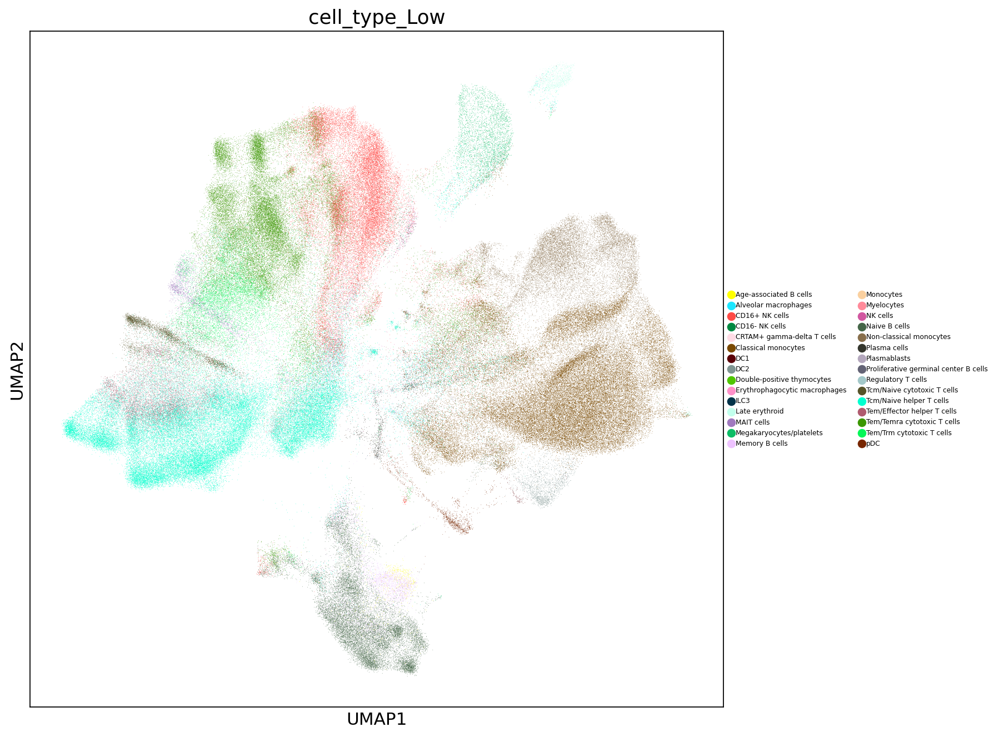

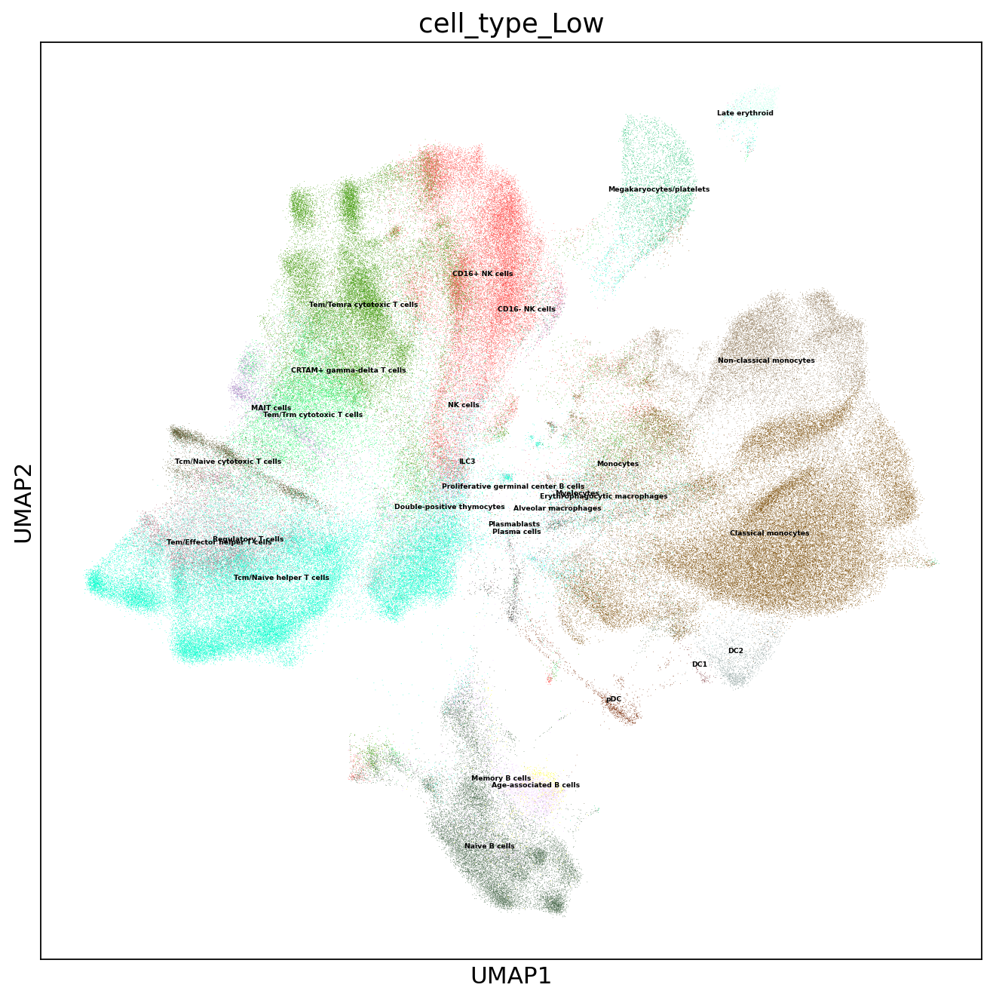

In [61]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type_Low'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type_Low'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type_Low'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_Low'])

sc.pl.umap(adata3, color=['cell_type_Low'], legend_loc = "on data", legend_fontsize= 'x-small')




In [62]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "cell_type_Low"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


Age-associated B cells → kept 500 / 577 cells
Alveolar macrophages → kept 500 / 540 cells
CD16+ NK cells       → kept 500 / 27852 cells
CD16- NK cells       → kept 500 / 533 cells
CRTAM+ gamma-delta T cells → kept 226 / 226 cells
Classical monocytes  → kept 500 / 57235 cells
DC1                  → kept 121 / 121 cells
DC2                  → kept 500 / 2042 cells
Double-positive thymocytes → kept 161 / 161 cells
Erythrophagocytic macrophages → kept 314 / 314 cells
ILC3                 → kept 121 / 121 cells
Late erythroid       → kept 500 / 1440 cells
MAIT cells           → kept 500 / 2542 cells
Megakaryocytes/platelets → kept 500 / 3550 cells
Memory B cells       → kept 500 / 4731 cells
Monocytes            → kept 122 / 122 cells
Myelocytes           → kept 182 / 182 cells
NK cells             → kept 500 / 2491 cells
Naive B cells        → kept 500 / 17408 cells
Non-classical monocytes → kept 500 / 16646 cells
Plasma cells         → kept 500 / 1615 cells
Plasmablasts         → kept 273

In [63]:
sc.tl.rank_genes_groups(adata_sub, groupby='cell_type_Low', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [64]:
sc.tl.leiden(
    adata3,
    resolution=2,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r2" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '9', '18', '7', '5', ..., '15', '20', '49', '47', '48']
Length: 50
Categories (50, object): ['0', '1', '2', '3', ..., '46', '47', '48', '49']


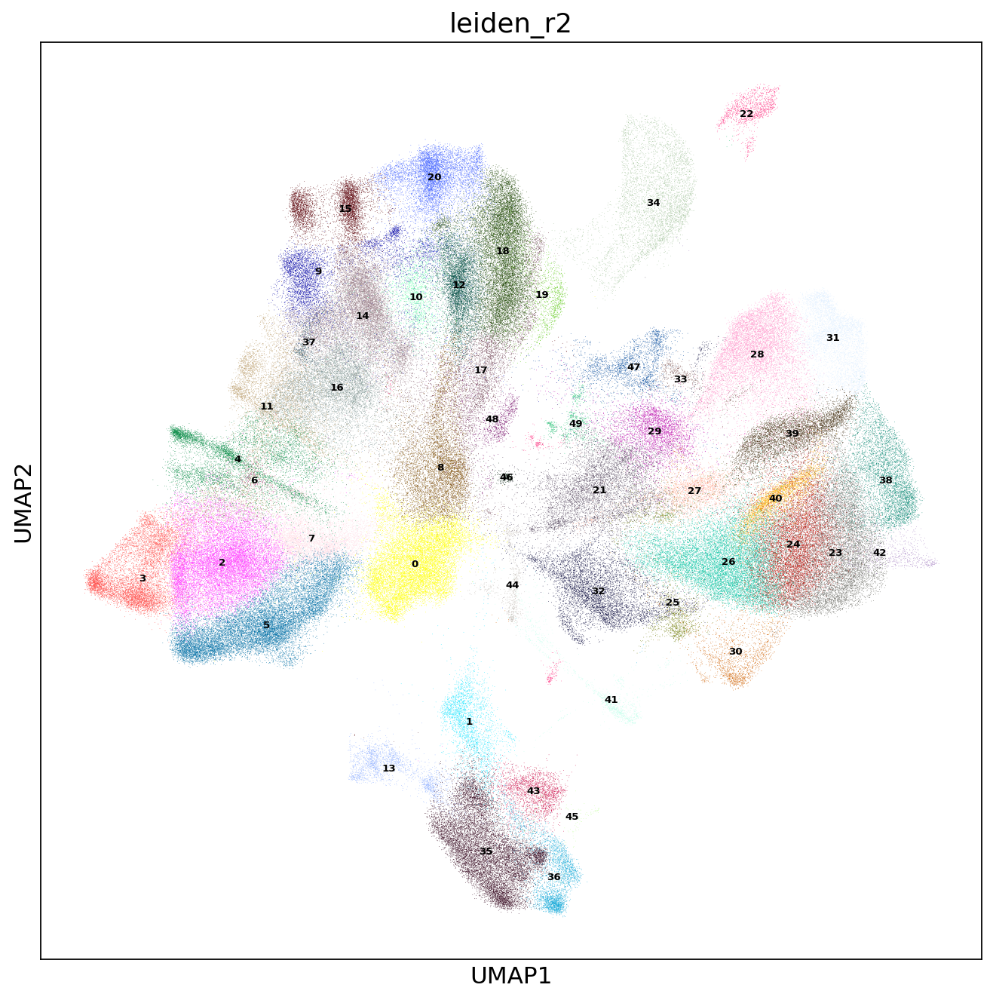

In [65]:
print(adata3.obs['leiden_r2'].unique())
sc.pl.umap(adata3, color='leiden_r2', legend_loc='on data')

In [66]:
sc.tl.leiden(
    adata3,
    resolution=0.4,
    random_state=0,
    flavor="igraph",
    n_iterations=2,
    directed=False,
    key_added="leiden_r0.4" 
) #Using igraph as flavor there is currently a bug on windows system that block freeze R.

['0', '7', '4', '3', '10', ..., '8', '15', '16', '14', '2']
Length: 17
Categories (17, object): ['0', '1', '2', '3', ..., '13', '14', '15', '16']


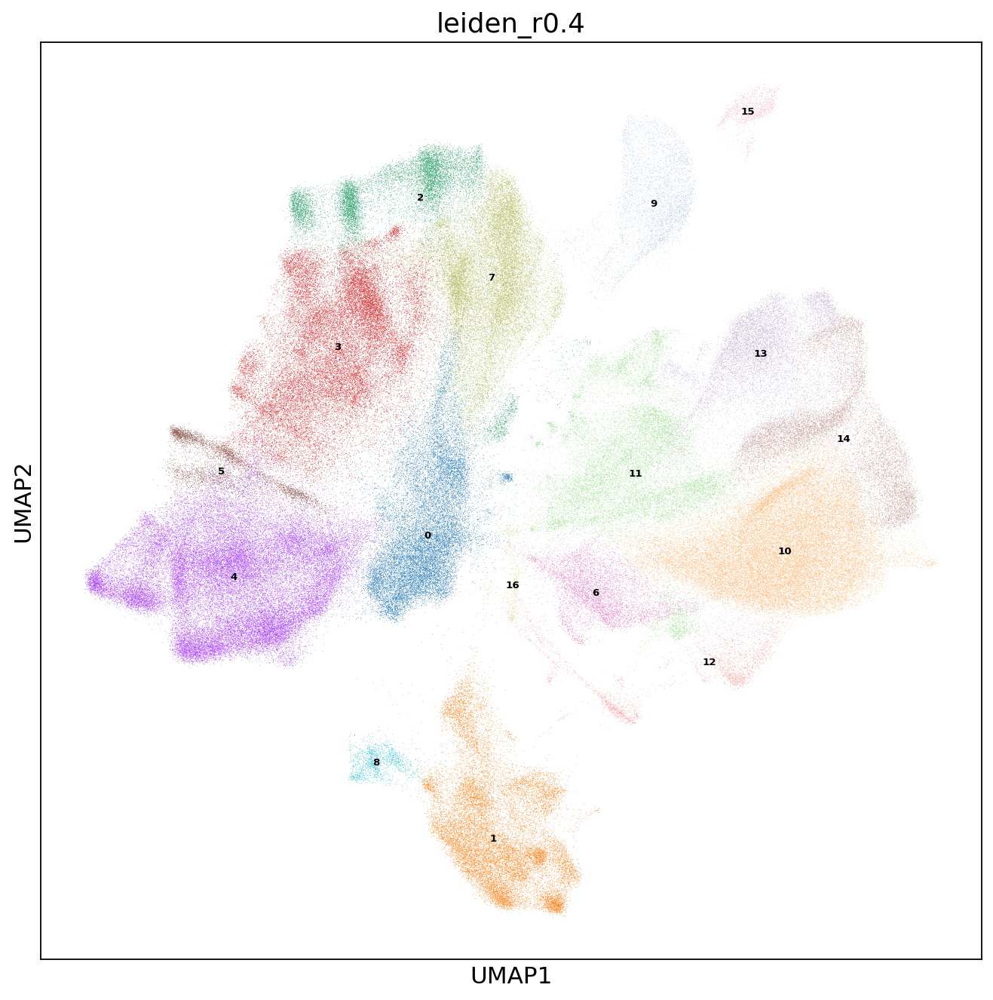

In [67]:
print(adata3.obs['leiden_r0.4'].unique())
sc.pl.umap(adata3, color='leiden_r0.4', legend_loc='on data')

In [68]:
import numpy as np
import pandas as pd
import scanpy as sc

# Set parameters
min_keep = 500        # minimum cells to keep per cell type
groupby = "leiden_r0.4"  # column defining populations

# Prepare empty index list
subsampled_idx = []

# Loop through each cell type and subsample
for cell_type, indices in adata3.obs.groupby(groupby).groups.items():
    n_cells = len(indices)
    if n_cells <= min_keep:
        chosen = indices  # keep all
    else:
        chosen = np.random.choice(indices, size=min_keep, replace=False)
    subsampled_idx.extend(chosen)
    print(f"{cell_type:<20} → kept {len(chosen)} / {n_cells} cells")

# Create subsampled AnnData
adata_sub = adata3[subsampled_idx, :].copy()

print(f"\nTotal cells before: {adata3.n_obs}")
print(f"Total cells after subsampling: {adata_sub.n_obs}")


0                    → kept 500 / 20166 cells
1                    → kept 500 / 20398 cells
2                    → kept 500 / 12583 cells
3                    → kept 500 / 32881 cells
4                    → kept 500 / 44209 cells
5                    → kept 500 / 4984 cells
6                    → kept 500 / 5948 cells
7                    → kept 500 / 23328 cells
8                    → kept 500 / 1481 cells
9                    → kept 500 / 4768 cells
10                   → kept 500 / 34789 cells
11                   → kept 500 / 17353 cells
12                   → kept 500 / 3320 cells
13                   → kept 500 / 10634 cells
14                   → kept 500 / 12857 cells
15                   → kept 500 / 1447 cells
16                   → kept 500 / 755 cells

Total cells before: 251901
Total cells after subsampling: 8500


Keeping 30 cell types with ≥ 50 cells
Remaining cells: 251901
Remaining cell types: 30


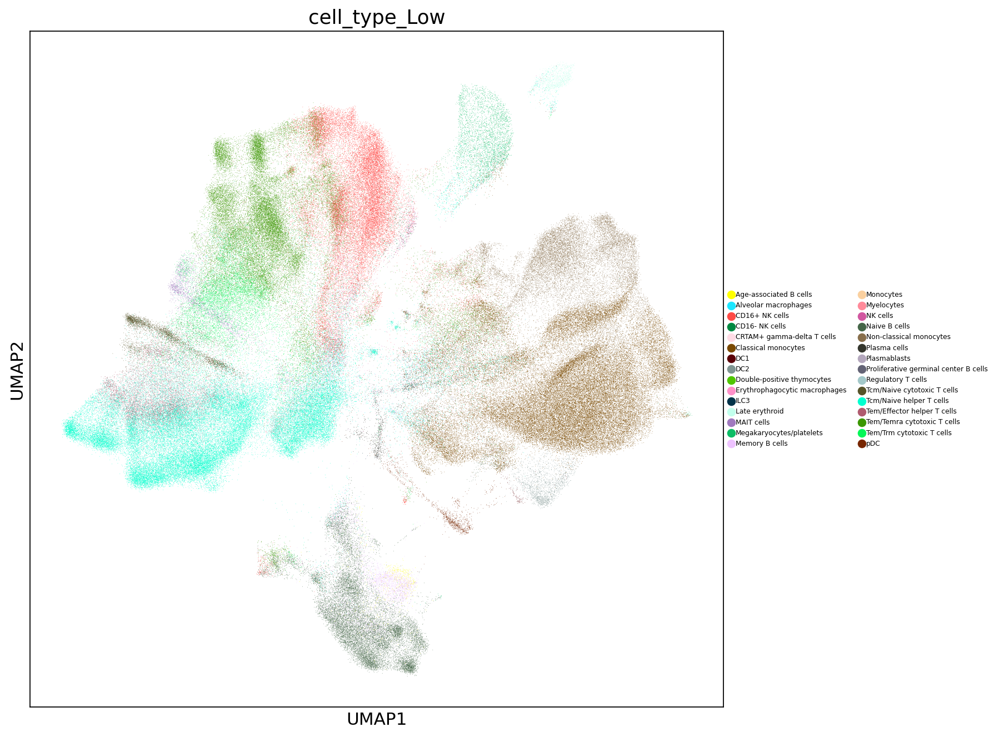

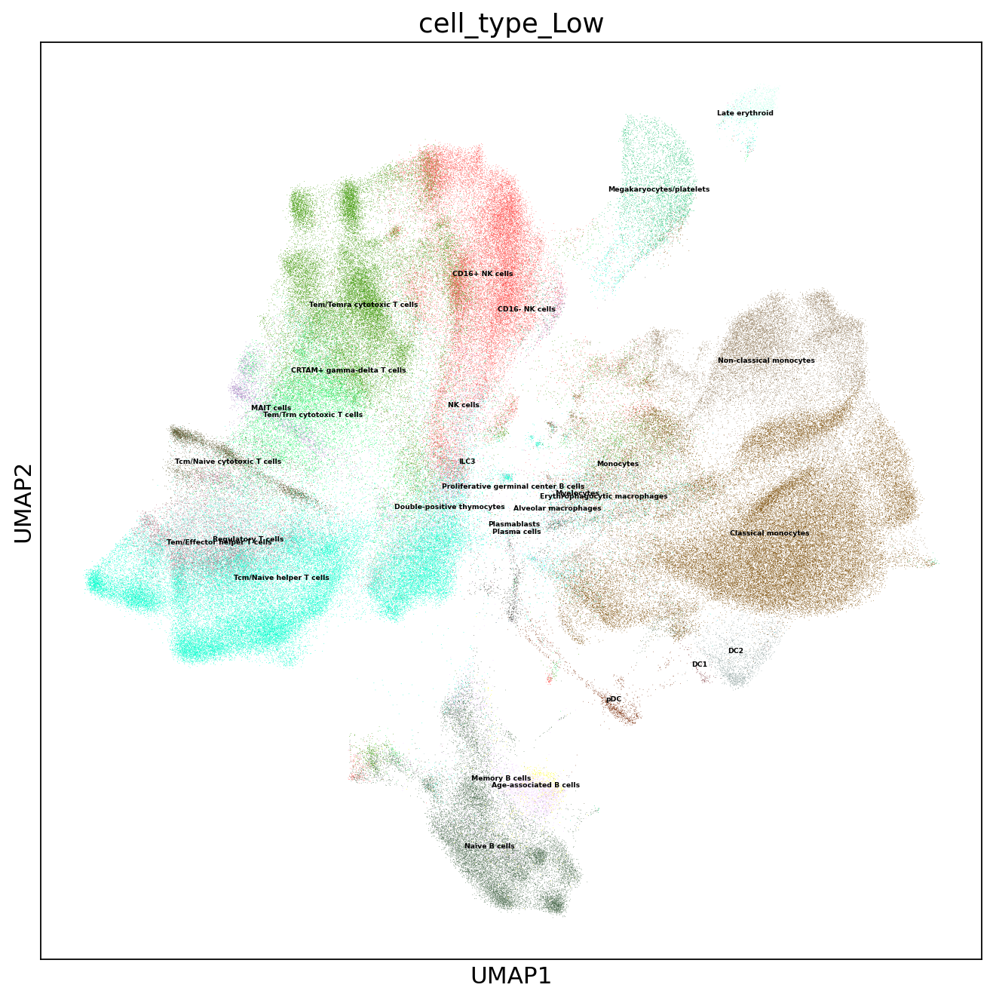

In [69]:
import pandas as pd

# Define the minimum cell count threshold
min_cells = 50

# Count cells per cell type
celltype_counts = adata3.obs['cell_type_Low'].value_counts()

# Identify cell types that meet the threshold
valid_celltypes = celltype_counts[celltype_counts >= min_cells].index

print(f"Keeping {len(valid_celltypes)} cell types with ≥ {min_cells} cells")

# Filter AnnData to keep only valid cell types
adata3 = adata3[adata3.obs['cell_type_Low'].isin(valid_celltypes)].copy()

# Report the result
print(f"Remaining cells: {adata3.n_obs}")
print(f"Remaining cell types: {adata3.obs['cell_type_Low'].nunique()}")



plt.rcParams["figure.figsize"] = (10, 10)

# Visualize the results in UMAP
sc.pl.umap(adata3, color=['cell_type_Low'])

sc.pl.umap(adata3, color=['cell_type_Low'], legend_loc = "on data", legend_fontsize= 'x-small')




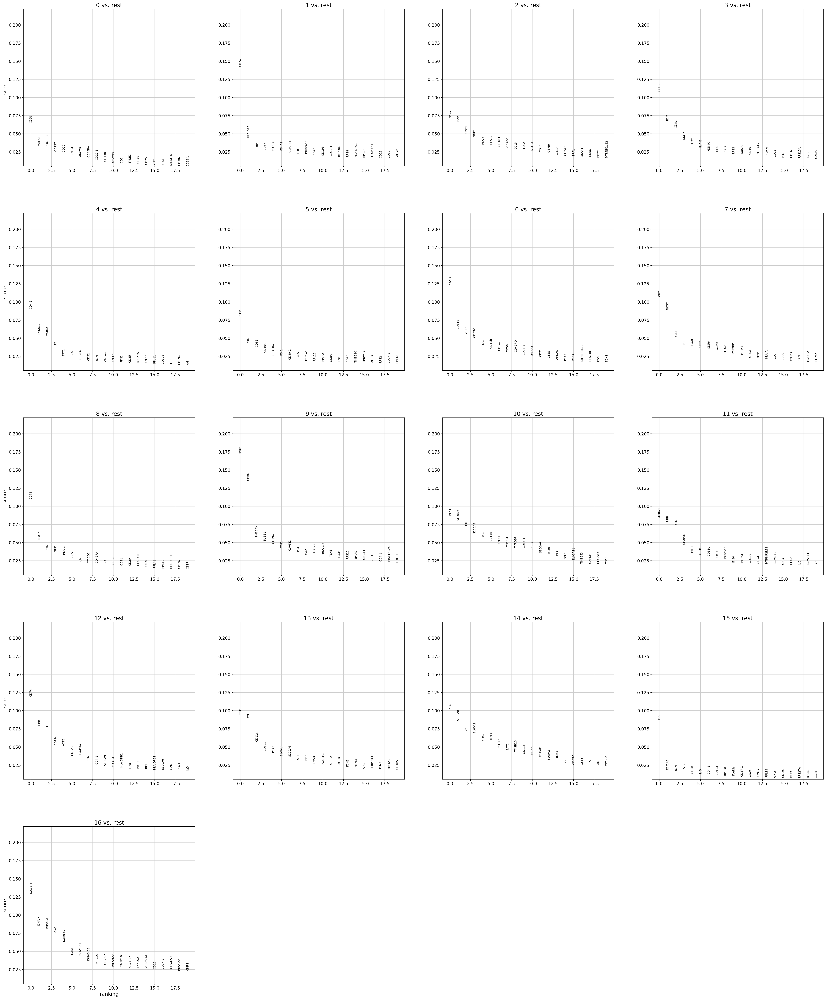

In [70]:
sc.tl.rank_genes_groups(adata_sub, groupby='leiden_r0.4', method='logreg')
sc.pl.rank_genes_groups(adata_sub)

In [71]:
adata3.write("/home/ciperi/data/Atlas_SSC/PBMCs/Unintegrated_PBMCs_V2_reann.h5ad")